<div align="center">

**ESCOLA SUPERIOR DE TECNOLOGIA – EST**<br>
Coordenação de Sistemas de Informação

# Trabalho Prático TP1
## Análise Exploratória de Dados: Netflix e Desempenho de Estudantes

</div>

| | |
|---|---|
| **Disciplina** | Ciência de Dados 1 — Período 2026/02 |
| **Professor** | Márcio Palheta Piedade, D.Sc. |
| **Aluno** | Caio Bertoldo Bezerra |
| **Modalidade** | Individual |
| **Entrega / Defesa** | 19/10 · 20 e 22/10 |

## Objetivo

Realizar uma análise exploratória de duas bases reais, aplicando os recursos estudados na
disciplina: **DataFrames, leitura de arquivos, seleção, filtros, indexação, estatísticas
descritivas e visualização**.

| Base | Fonte | Conteúdo |
|---|---|---|
| **1. Netflix Movies and TV Shows** | [Kaggle — shivamb/netflix-shows](https://www.kaggle.com/datasets/shivamb/netflix-shows) | Filmes e séries do catálogo: tipo, título, diretor, elenco, país, ano de lançamento, classificação e duração |
| **2. Students Performance in Exams** | [Kaggle — spscientist/students-performance-in-exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams) | Notas de Matemática, Leitura e Escrita de 1.000 estudantes, com gênero, grupo, escolaridade dos pais, alimentação e curso preparatório |

## Sumário

**0. Preparação do ambiente**

**Parte I — Netflix Movies and TV Shows**
1. Conhecendo e preparando os dados *(1,0 pt)*
2. Investigação dos dados *(1,2 pt)*
3. Visualização dos dados *(0,8 pt)*

**Parte II — Students Performance in Exams**

4. Conhecendo e preparando os dados *(1,0 pt)*
5. Análise do desempenho dos estudantes *(1,5 pt)*
6. Visualização dos dados *(1,0 pt)*

**Parte III — Investigação livre e conclusões**

7. Investigação livre — 2 perguntas por base *(1,0 pt)*
8. Conclusões *(0,5 pt)*

---

**Convenções usadas no notebook**

- Cada questão segue a sequência **pergunta → código → resultado → interpretação**.
- Os DataFrames originais (`netflix` e `alunos`) **não são alterados**. Quando um tratamento é
  necessário, ele é feito em uma cópia, e a decisão é justificada no texto.
- Todos os números citados nas interpretações foram obtidos a partir das células de código
  imediatamente anteriores.

---
# 0. Preparação do ambiente

## 0.1 Bibliotecas e configurações

Bibliotecas utilizadas:

- **pandas**: leitura dos arquivos CSV e manipulação dos dados em DataFrames;
- **matplotlib**: construção dos gráficos;
- **os**: verificação da existência dos arquivos na pasta de trabalho.

Também são definidas as configurações visuais aplicadas a todos os gráficos, como tamanho,
fontes e grade discreta, e uma paleta de cores fixa. Assim, todas as figuras do trabalho
mantêm o mesmo padrão.

> **Versão do pandas:** o notebook usa apenas recursos básicos do pandas e foi executado sem
> erros com o **pandas 2.3** e com o **pandas 3.0**. O Google Colab pode trazer outra versão
> instalada. Por isso, a célula abaixo **exibe a versão realmente usada** em cada execução. A
> única diferença visível entre as versões é o nome do tipo das colunas de texto: `object` no
> pandas 2 e `str` no pandas 3.

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

# Exibição das tabelas do pandas
pd.set_option('display.max_columns', None)   # mostra todas as colunas
pd.set_option('display.max_colwidth', 50)    # limita textos longos (ex.: descrição)
pd.set_option('display.float_format', '{:.2f}'.format)  # números com 2 casas decimais

# Padrão visual dos gráficos
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 100,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': 11,
    'axes.labelcolor': '#52514e',
    'axes.edgecolor': '#b5b4ad',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,       # grade atrás das barras
    'grid.color': '#e5e4df',
    'grid.linewidth': 0.8,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'legend.frameon': False,
})

# Paleta de cores do trabalho
COR_NETFLIX = '#e34948'   # vermelho: gráficos de uma única série da base Netflix
COR_ALUNOS = '#2a78d6'    # azul: gráficos de uma única série da base de estudantes
CORES = ['#2a78d6', '#eb6834', '#1baf7a']  # azul, laranja, verde-água (comparação de categorias)

print('Versão do pandas em uso:', pd.__version__)
print('Ambiente configurado.')

Versão do pandas em uso: 3.0.6
Ambiente configurado.


## 0.2 Localização dos arquivos

Os arquivos foram baixados do Kaggle e devem estar na **mesma pasta do notebook**:

- `netflix_titles.csv`
- `StudentsPerformance.csv`

**No Google Colab:** se os arquivos ainda não estiverem na sessão, a célula abaixo abre uma janela
para selecioná-los no computador.

**Fora do Colab** (Jupyter, VS Code): basta manter os CSVs ao lado do notebook. Se algum arquivo
estiver faltando, a execução é interrompida com uma mensagem que informa **qual arquivo falta** e
**em qual pasta ele deve ser colocado**.

In [2]:
ARQUIVO_NETFLIX = 'netflix_titles.csv'
ARQUIVO_ALUNOS = 'StudentsPerformance.csv'

faltando = []
for arquivo in [ARQUIVO_NETFLIX, ARQUIVO_ALUNOS]:
    if not os.path.exists(arquivo):
        faltando.append(arquivo)

if len(faltando) > 0:
    # Verifica se o notebook está rodando no Google Colab (o módulo google.colab só existe lá)
    try:
        from google.colab import files
        no_colab = True
    except ImportError:
        no_colab = False

    if no_colab:
        print('Selecione os arquivos:', faltando)
        files.upload()
    else:
        raise FileNotFoundError(
            f'Arquivo(s) não encontrado(s): {faltando}. '
            f'Coloque os CSVs baixados do Kaggle nesta pasta: {os.getcwd()}'
        )

# Conferência final (também detecta um upload com nome diferente, ex.: "netflix_titles (1).csv")
for arquivo in [ARQUIVO_NETFLIX, ARQUIVO_ALUNOS]:
    if not os.path.exists(arquivo):
        raise FileNotFoundError(f'{arquivo} continua ausente. Confira se o nome do arquivo enviado está exatamente igual.')
    tamanho_kb = os.path.getsize(arquivo) / 1024
    print(f'{arquivo:<26} encontrado ({tamanho_kb:.0f} KB)')

netflix_titles.csv         encontrado (3320 KB)
StudentsPerformance.csv    encontrado (70 KB)


---
<div align="center">

# PARTE I — Netflix Movies and TV Shows

</div>

Cada linha da base representa **um título** (filme ou série) disponível no catálogo da Netflix.
Principais colunas:

| Coluna | Significado |
|---|---|
| `show_id` | identificador único do título |
| `type` | `Movie` (filme) ou `TV Show` (série) |
| `title` | título |
| `director` / `cast` | diretor(es) e elenco (podem conter vários nomes separados por vírgula) |
| `country` | país(es) de produção (também pode conter vários) |
| `date_added` | data em que o título **entrou no catálogo** da Netflix |
| `release_year` | ano de **lançamento original** da obra |
| `rating` | classificação indicativa (ex.: `TV-MA`, `PG-13`) |
| `duration` | duração: minutos para filmes (`90 min`), temporadas para séries (`2 Seasons`) |
| `listed_in` | gêneros/categorias |
| `description` | sinopse |

> **Atenção:** `release_year` (ano de lançamento) e `date_added` (data de inclusão no catálogo)
> são informações diferentes. Um filme de 1980 pode ter sido adicionado à Netflix em 2019.

---
# 1. Conhecendo e preparando os dados

## 1.1 Carga do arquivo CSV

A função `pd.read_csv()` lê o arquivo e cria um **DataFrame**, uma tabela em que cada linha é um
registro e cada coluna é um atributo.

In [3]:
netflix = pd.read_csv(ARQUIVO_NETFLIX)

print('Base Netflix carregada com sucesso.')
print('Linhas:', netflix.shape[0], '| Colunas:', netflix.shape[1])

Base Netflix carregada com sucesso.
Linhas: 8807 | Colunas: 12


**Conferência da carga.** A página do Kaggle informa que a base possui **8.807 títulos** e
**12 colunas**. A célula abaixo compara esses valores com o que foi lido e verifica se os
caracteres acentuados foram interpretados corretamente. Se a codificação estivesse errada,
`Pokémon` apareceria como `PokÃ©mon`.

In [4]:
print('Quantidade esperada confere?', netflix.shape == (8807, 12))

# Títulos com acento: verificam se a codificação UTF-8 foi lida corretamente
netflix.loc[netflix['title'].str.contains('Pokémon|São Paulo'), ['show_id', 'type', 'title']]

Quantidade esperada confere? True


,show_id,type,title
85,s86,TV Show,Pokémon Master Journeys: The Series
455,s456,Movie,Emicida: AmarElo - Live in São Paulo
1235,s1236,TV Show,Pokémon Journeys: The Series
2739,s2740,TV Show,Pokémon the Series
2876,s2877,Movie,Pokémon: Mewtwo Strikes Back - Evolution
3069,s3070,Movie,Pokémon the Movie: Power of Us
4223,s4224,Movie,Pokémon the Movie: I Choose You!
5098,s5099,TV Show,Pokémon: Indigo League


## 1.2 Quantidade de linhas e colunas

O atributo `shape` devolve uma tupla `(linhas, colunas)`.

In [5]:
linhas, colunas = netflix.shape
print(f'A base possui {linhas} linhas (títulos) e {colunas} colunas (atributos).')

A base possui 8807 linhas (títulos) e 12 colunas (atributos).


Cada uma das **8.807 linhas** é um título do catálogo, e cada uma das **12 colunas** é uma
característica desse título.

## 1.3 Cinco primeiras e cinco últimas linhas

In [6]:
netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [7]:
netflix.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


**O que se observa:** já nas primeiras linhas aparecem valores ausentes (`NaN`). Por exemplo,
*Dick Johnson Is Dead* não tem elenco (`cast`) e *Blood & Water* não tem diretor (`director`).
A coluna `duration` mistura minutos (`90 min`) com temporadas (`2 Seasons`), dependendo do tipo
do título. Também há várias colunas com **mais de um valor na mesma célula**, separados por
vírgula: elenco, países e categorias.

## 1.4 Colunas existentes

In [8]:
print('Quantidade de colunas:', len(netflix.columns))
list(netflix.columns)

Quantidade de colunas: 12


['show_id',
 'type',
 'title',
 'director',
 'cast',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'listed_in',
 'description']

## 1.5 Tipos de dados

In [9]:
netflix.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

**Interpretação dos tipos:**

- Apenas `release_year` foi lido como número (`int64`). Todas as outras colunas são **texto**,
  exibido como `object` no pandas 2 ou `str` no pandas 3.
- `date_added` é uma data, mas foi lida como texto (`"September 25, 2021"`). Para fazer cálculos
  com ela, como extrair o ano, é preciso convertê-la para o tipo data (`datetime`), o que é feito
  no item 1.10.
- `duration` também é texto e mistura duas unidades: **minutos** (filmes) e **temporadas**
  (séries). Para calcular estatísticas de duração dos filmes, é necessário separar os filmes e
  extrair a parte numérica (questão 2.7).

## 1.6 Valores ausentes por coluna

`isna()` marca cada célula vazia como `True`. Somando por coluna (`sum()`), obtemos a quantidade
de ausentes. A média (`mean()`) dá a proporção, que multiplicada por 100 vira percentual.

In [10]:
ausentes = pd.DataFrame({
    'ausentes': netflix.isna().sum(),
    'percentual (%)': netflix.isna().mean() * 100,
})
ausentes.sort_values('ausentes', ascending=False)

,ausentes,percentual (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


**Interpretação:** seis das doze colunas têm valores ausentes.

- **`director`** é a mais afetada: **2.634 títulos (29,9%)** não informam diretor. O item 1.9
  mostra que isso se concentra nas séries.
- **`country`** (831; 9,4%) e **`cast`** (825; 9,4%) também têm lacunas relevantes. Nas questões
  sobre países, esses títulos não podem ser contabilizados.
- **`date_added`** (10), **`rating`** (4) e **`duration`** (3) têm poucos ausentes. Os 3 de
  `duration`, porém, escondem um erro de digitação, investigado no item 1.9.

## 1.7 Registros duplicados

Primeiro verificamos duplicatas **exatas**, ou seja, linhas idênticas em todas as colunas. Depois
verificamos o identificador `show_id` e o título.

In [11]:
print('Linhas totalmente duplicadas:', netflix.duplicated().sum())
print('show_id repetidos           :', netflix['show_id'].duplicated().sum())
print('Títulos exatamente repetidos:', netflix['title'].duplicated().sum())

Linhas totalmente duplicadas: 0
show_id repetidos           : 0
Títulos exatamente repetidos: 0


Não há duplicatas exatas. Porém, a comparação exata diferencia letras maiúsculas e minúsculas e
espaços extras, e isso pode esconder **quase-duplicatas**. Para investigá-las, criamos uma versão
**normalizada** do título, toda em minúsculas (`str.lower()`) e sem espaços nas pontas
(`str.strip()`), e procuramos títulos que se repetem nessa versão.

In [12]:
titulo_normalizado = netflix['title'].str.lower().str.strip()
repetido = titulo_normalizado.duplicated(keep=False)   # keep=False marca todas as ocorrências

print('Títulos repetidos após normalização:', repetido.sum(), 'registros')

quase_duplicatas = netflix[repetido].copy()
quase_duplicatas['titulo_normalizado'] = titulo_normalizado[repetido]
quase_duplicatas.sort_values('titulo_normalizado')[
    ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration']
]

Títulos repetidos após normalização: 12 registros


,show_id,type,title,director,country,date_added,release_year,rating,duration
3371,s3372,Movie,Consequences,Ozan Açıktan,Turkey,"October 25, 2019",2014,TV-MA,106 min
6529,s6530,Movie,Consequences,Ozan Açıktan,Turkey,"October 25, 2019",2014,TV-MA,106 min
5318,s5319,Movie,Death Note,Adam Wingard,United States,"August 25, 2017",2017,TV-MA,100 min
5751,s5752,TV Show,DEATH NOTE,NaN,Japan,"October 15, 2016",2006,TV-14,1 Season
303,s304,Movie,Esperando la carroza,Alejandro Doria,Argentina,"August 5, 2021",1985,TV-MA,95 min
6705,s6706,Movie,Esperando La Carroza,Alejandro Doria,Argentina,"July 15, 2018",1985,NR,95 min
5033,s5034,Movie,FullMetal Alchemist,Fumihiko Sori,Japan,"February 19, 2018",2017,TV-PG,134 min
5095,s5096,TV Show,Fullmetal Alchemist,NaN,Japan,"January 1, 2018",2003,TV-14,1 Season
159,s160,Movie,Love in a Puff,Pang Ho-cheung,Hong Kong,"September 1, 2021",2010,TV-MA,103 min
7345,s7346,Movie,Love In A Puff,Pang Ho-cheung,Hong Kong,"August 1, 2018",2010,TV-MA,103 min


**Investigação dos 6 pares encontrados:**

| Par | O que mostram os dados | Conclusão |
|---|---|---|
| *Death Note* / *DEATH NOTE* | um é filme americano de 2017; o outro, série japonesa de 2006 | **obras diferentes**, devem ser mantidas |
| *FullMetal Alchemist* / *Fullmetal Alchemist* | filme de 2017 × série de 2003 | **obras diferentes**, devem ser mantidas |
| *Consequences* | todas as colunas iguais, inclusive a data de inclusão; um dos títulos termina com um espaço invisível (`\xa0`) | **duplicata real** |
| *Esperando la carroza*, *Love in a Puff*, *Sin senos sí hay paraíso* | mesmo tipo, ano, país e duração; nos dois filmes o diretor também coincide, enquanto a série não informa diretor em nenhum dos dois registros; datas de inclusão diferentes (2018/2019 e 2021) | **mesma obra cadastrada duas vezes**. Uma hipótese é que o título tenha saído do catálogo e voltado, mas **a base não permite confirmar isso**, pois não registra saídas de títulos |

**Decisão:** como a seção 2 conta **produções**, cada obra deve ser contada uma única vez. Na
**cópia de trabalho** (item 1.10), consideramos duplicados os registros com o mesmo título
normalizado, o mesmo tipo e o mesmo ano de lançamento. Esse critério remove exatamente
**4 registros** (0,05% da base) e preserva *Death Note* e *Fullmetal Alchemist*, que diferem no
tipo e no ano. O DataFrame original `netflix` continua com os 8.807 registros.

## 1.8 Descrição inicial da base

`describe()` resume as colunas numéricas. Com `exclude='number'`, ele resume as colunas de texto.

In [13]:
netflix.describe()

,release_year
count,8807.00
mean,2014.18
std,8.82
min,1925.00
25%,2013.00
50%,2017.00
75%,2019.00
max,2021.00


**O que esses números representam (coluna `release_year`):**

- `count = 8807`: todos os títulos têm ano de lançamento, sem ausentes.
- `min = 1925` e `max = 2021`: o título mais antigo foi lançado em 1925; os mais recentes, em 2021.
- `50% = 2017` (mediana): **metade dos títulos foi lançada em 2017 ou depois**.
- `25% = 2013` (1º quartil): **75% dos títulos foram lançados a partir de 2013**.
- `mean ≈ 2014,2` é **menor** que a mediana, porque os poucos títulos muito antigos puxam a média
  para baixo. Isso indica uma distribuição assimétrica, concentrada em anos recentes com uma cauda
  longa de títulos antigos.
- `std ≈ 8,8` anos (desvio padrão): mede a dispersão dos anos em torno da média.

In [14]:
netflix.describe(exclude='number')

,show_id,type,title,director,cast,country,date_added,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,3207,1793,362,4


**O que esses números representam (colunas de texto):**

- `count`: quantidade de valores **não ausentes**. Por exemplo, `director` tem 6.173 de 8.807.
- `unique`: quantidade de valores **distintos**. `show_id` e `title` têm 8.807 valores únicos;
  `type` tem apenas 2 (`Movie` e `TV Show`).
- `top` / `freq`: o valor mais frequente e quantas vezes aparece. É preciso cuidado ao ler esses
  campos nas colunas com vários nomes:
  - em `country`, `top = United States` com `freq = 2818` conta apenas os títulos em que o país é
    **exclusivamente** "United States". Coproduções como "United States, India" não entram;
  - em `director`, `top = Rajiv Chilaka` aparece 19 vezes sozinho, mas ele também dirige títulos
    em parceria. A contagem completa só é obtida separando os nomes (questão 2.3).
- `rating` tem 17 valores distintos, mas, como mostra o item 1.9, três deles não são classificações.
- `date_added`: o valor mais frequente é `January 1, 2020`, com 109 títulos. Isso sugere inclusões
  em lote no primeiro dia do ano.
- `description` tem 8.775 valores únicos para 8.807 títulos, ou seja, **32 registros repetem
  uma sinopse que já apareceu** em outro título. Isso reforça a investigação de quase-duplicatas feita no item 1.7.

## 1.9 Características e problemas encontrados nos dados

As células a seguir mostram as evidências dos problemas, que são resumidos no texto ao final.

**(a) Valores na coluna errada:** registros em que `rating` contém uma duração em minutos.

In [15]:
erro_rating = netflix['rating'].str.contains('min', na=False)
netflix[erro_rating][['show_id', 'type', 'title', 'rating', 'duration']]

,show_id,type,title,rating,duration
5541,s5542,Movie,Louis C.K. 2017,74 min,NaN
5794,s5795,Movie,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,66 min,NaN


**(b) Diretor ausente:** a falta de diretor se concentra em algum tipo de título?

In [16]:
sem_diretor = netflix[netflix['director'].isna()]

pd.DataFrame({
    'sem diretor': sem_diretor['type'].value_counts(),
    'total do tipo': netflix['type'].value_counts(),
    'percentual (%)': sem_diretor['type'].value_counts() / netflix['type'].value_counts() * 100,
})

,sem diretor,total do tipo,percentual (%)
type,,,
Movie,188,6131,3.07
TV Show,2446,2676,91.41


**(c) Campos com vários valores:** quantos títulos têm mais de um país ou diretor, e se há
vírgulas sobrando no final do texto.

In [17]:
print('Títulos com mais de um país   :', netflix['country'].str.contains(',', na=False).sum())
print('Títulos com mais de um diretor:', netflix['director'].str.contains(',', na=False).sum())

virgula_final = netflix['country'].str.strip().str.endswith(',', na=False)
netflix[virgula_final][['show_id', 'title', 'country']]

Títulos com mais de um país   : 1320
Títulos com mais de um diretor: 614


,show_id,title,country
1192,s1193,The Present,"United Kingdom,"
2224,s2225,Funan,"France, Belgium, Luxembourg, Cambodia,"
4653,s4654,City of Joy,"United States,"
5925,s5926,Virunga,"United Kingdom,"
7007,s7008,Hotel Pacific,"Poland,"


**(d) Datas:** `date_added` tem espaços extras no início? Algum título aparece como incluído no
catálogo **antes** de ter sido lançado?

In [18]:
print('Datas com espaço no início:', netflix['date_added'].str.startswith(' ', na=False).sum())

# Conversão temporária apenas para a verificação (o original não é alterado)
ano_inclusao = pd.to_datetime(netflix['date_added'].str.strip(), format='%B %d, %Y').dt.year
incluido_antes = netflix[ano_inclusao < netflix['release_year']]

print('Títulos incluídos antes do ano de lançamento:', len(incluido_antes))
incluido_antes['type'].value_counts()

Datas com espaço no início: 88
Títulos incluídos antes do ano de lançamento: 14


type
TV Show    12
Movie       2
Name: count, dtype: int64

**Síntese das características e problemas encontrados:**

1. **Muitos valores ausentes em `director`:** 29,9% dos títulos não informam diretor. Isso afeta
   principalmente as **séries**: cerca de 91% delas não têm diretor, contra apenas 3% dos filmes.
   Assim, qualquer análise de diretores praticamente só descreve filmes.
2. **Campos com vários valores na mesma célula:** `country` (1.320 títulos com mais de um país),
   `director` (614 com mais de um diretor), `cast` e `listed_in` guardam listas em forma de texto
   separadas por vírgula. Para contar países ou diretores, é preciso separar esses nomes. Além
   disso, 5 registros de `country` terminam com uma vírgula sobrando, o que geraria um "país vazio"
   se não fosse tratado.
3. **Valores na coluna errada:** em 3 especiais de stand-up de Louis C.K., a duração (`74 min`,
   `84 min`, `66 min`) foi gravada em `rating`, e `duration` ficou vazia. É um erro de
   preenchimento: o valor existe, mas está no lugar errado.
4. **Tipos inadequados:** `date_added` é texto, com 88 valores começando por um espaço, e
   `duration` é texto que mistura minutos e temporadas. Nenhuma das duas pode ser usada em
   cálculos sem conversão.
5. **Quase-duplicatas:** não existem linhas idênticas, mas há 4 registros que repetem uma mesma
   obra (item 1.7).
6. **Inconsistência entre datas:** 14 títulos, a maioria séries, aparecem como incluídos no
   catálogo antes do ano de lançamento. Uma explicação provável é que, nas séries,
   `release_year` registre o ano da temporada mais recente, e não o da estreia. Como a base não
   documenta isso, os registros foram **mantidos**, e a observação fica registrada como limitação.

## 1.10 Preparação da cópia de trabalho (`netflix_tratado`)

Para **preservar os dados originais**, todos os tratamentos são feitos em uma cópia
(`netflix.copy()`). As seções 2 e 3 usam essa cópia.

| Problema | Tratamento | Justificativa |
|---|---|---|
| Quase-duplicatas (item 1.7) | remover 4 registros repetidos da mesma obra | contar cada produção uma única vez |
| Duração gravada em `rating` (Louis C.K.) | mover o valor para `duration` e deixar `rating` vazio | o valor é claramente uma duração, e assim os 3 filmes passam a ter duração válida |
| `date_added` como texto | criar `data_adicao` (data) e `ano_adicao` (ano) | permitir análises por ano de inclusão **sem apagar** a coluna original |
| Ausentes em `director`, `country`, `cast` | **mantidos** como ausentes | preencher com "Desconhecido" criaria um falso "país" ou "diretor" nos rankings; nas contagens, os ausentes são simplesmente ignorados e informados |

In [19]:
netflix_tratado = netflix.copy()

# 1) Quase-duplicatas: mesmo título normalizado + mesmo tipo + mesmo ano de lançamento
netflix_tratado['titulo_normalizado'] = netflix_tratado['title'].str.lower().str.strip()
duplicada = netflix_tratado.duplicated(subset=['titulo_normalizado', 'type', 'release_year'])
print('Registros removidos por duplicidade:', duplicada.sum())

netflix_tratado = netflix_tratado[~duplicada].copy()   # ~ inverte: mantém os NÃO duplicados
netflix_tratado = netflix_tratado.drop(columns='titulo_normalizado')

Registros removidos por duplicidade:

 4


Com `duplicated()`, a **primeira ocorrência** de cada obra é mantida e as seguintes são marcadas
como duplicadas. No arquivo, a primeira ocorrência é o cadastro mais recente, de 2021.

In [20]:
# 2) Duração gravada na coluna rating: move o valor para duration e deixa rating vazio
erro_rating = netflix_tratado['rating'].str.contains('min', na=False)
netflix_tratado.loc[erro_rating, 'duration'] = netflix_tratado.loc[erro_rating, 'rating']
netflix_tratado.loc[erro_rating, 'rating'] = None

netflix_tratado.loc[erro_rating, ['show_id', 'title', 'rating', 'duration']]

,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,NaN,74 min
5794,s5795,Louis C.K.: Hilarious,NaN,84 min
5813,s5814,Louis C.K.: Live at the Comedy Store,NaN,66 min


In [21]:
# 3) Data de inclusão no catálogo: texto -> data (o strip remove os espaços do início)
netflix_tratado['data_adicao'] = pd.to_datetime(netflix_tratado['date_added'].str.strip(), format='%B %d, %Y')

# Ano de inclusão. 'Int64' (com I maiúsculo) é o tipo inteiro do pandas que aceita valores ausentes
netflix_tratado['ano_adicao'] = netflix_tratado['data_adicao'].dt.year.astype('Int64')

netflix_tratado[['title', 'date_added', 'data_adicao', 'ano_adicao', 'release_year']].head()

,title,date_added,data_adicao,ano_adicao,release_year
0,Dick Johnson Is Dead,"September 25, 2021",2021-09-25,2021,2020
1,Blood & Water,"September 24, 2021",2021-09-24,2021,2021
2,Ganglands,"September 24, 2021",2021-09-24,2021,2021
3,Jailbirds New Orleans,"September 24, 2021",2021-09-24,2021,2021
4,Kota Factory,"September 24, 2021",2021-09-24,2021,2021


**Conferência:** a cópia tratada foi modificada, e o DataFrame original continua intacto.

In [22]:
print('Original (netflix)        :', netflix.shape)
print('Tratado  (netflix_tratado):', netflix_tratado.shape, '-> 4 registros a menos e 2 colunas novas')
print()
print('Durações dentro de rating no original:', netflix['rating'].str.contains('min', na=False).sum())
print('Durações dentro de rating no tratado :', netflix_tratado['rating'].str.contains('min', na=False).sum())
print()
print('Período de inclusão no catálogo:', netflix_tratado['data_adicao'].min().date(),
      'a', netflix_tratado['data_adicao'].max().date())

Original (netflix)        : (8807, 12)
Tratado  (netflix_tratado): (8803, 14) -> 4 registros a menos e 2 colunas novas

Durações dentro de rating no original: 3
Durações dentro de rating no tratado : 0

Período de inclusão no catálogo: 2008-01-01 a 2021-09-25


> **`release_year` × `date_added`:** a partir daqui, "**ano de lançamento**" se refere sempre a
> `release_year`, quando a obra foi lançada originalmente, e "**ano de inclusão**" se refere a
> `ano_adicao`, quando o título entrou no catálogo da Netflix. Os títulos foram incluídos entre
> 2008 e setembro de 2021, mas foram lançados entre 1925 e 2021.

---
# 2. Investigação dos dados

Todas as questões usam a cópia tratada `netflix_tratado`, com **8.803 títulos**.

### 2.1 Quantos registros correspondem a Movies e quantos a TV Shows?

`value_counts()` conta quantas vezes cada valor aparece. Com `normalize=True`, ele devolve a
proporção em vez da contagem.

In [23]:
contagem_tipo = netflix_tratado['type'].value_counts()
percentual_tipo = netflix_tratado['type'].value_counts(normalize=True) * 100

pd.DataFrame({'quantidade': contagem_tipo, 'percentual (%)': percentual_tipo})

,quantidade,percentual (%)
type,,
Movie,6128,69.61
TV Show,2675,30.39


**Interpretação:** o catálogo é formado principalmente por **filmes**: 6.128 títulos, cerca de
**70%**, contra 2.675 séries (30%). Há aproximadamente **2,3 filmes para cada série**. Na base
original, sem a remoção das quase-duplicatas, os números seriam 6.131 e 2.676. A diferença é
pequena e não altera a conclusão.

Uma ressalva: a base conta **títulos**, não horas de conteúdo. Uma série com várias temporadas
vale o mesmo que um filme de 90 minutos.

### 2.2 Quais são os 10 países com maior quantidade de produções?

A coluna `country` pode ter **vários países no mesmo texto** (`"United States, India"`). Por isso:

1. `dropna()` descarta os títulos sem país, que não podem ser contados;
2. `str.split(',')` transforma o texto em uma lista de países;
3. `explode()` coloca cada país da lista em uma linha própria;
4. `str.strip()` remove os espaços que sobram depois da vírgula (`" India"` → `"India"`);
5. os textos vazios, gerados por vírgulas no final, são descartados.

**Consequência importante:** uma coprodução é contada **uma vez para cada país participante**.
Por isso, a soma das contagens por país é maior que o número de títulos.

In [24]:
paises = netflix_tratado['country'].dropna().str.split(',').explode().str.strip()
print('Valores vazios descartados:', (paises == '').sum())
paises = paises[paises != '']

print('Títulos com país informado  :', netflix_tratado['country'].notna().sum())
print('Total de menções a países   :', len(paises))
print('Quantidade de países únicos :', paises.nunique())

Valores vazios descartados: 7
Títulos com país informado  : 7972
Total de menções a países   : 10007
Quantidade de países únicos : 122


**Ordenação com desempate:** quando dois valores têm a mesma contagem, a ordem devolvida por
`value_counts()` pode variar entre versões do pandas. Para que o resultado seja sempre o mesmo,
primeiro ordenamos pelo nome (`sort_index()`) e depois pela quantidade, com `kind='stable'`. Esse
tipo de ordenação mantém a ordem alfabética entre os empatados. O mesmo critério é usado nas
questões 2.3 e 2.7.

In [25]:
contagem_paises = paises.value_counts().sort_index().sort_values(ascending=False, kind='stable')
top10_paises = contagem_paises.head(10)

# Conferência de empate na fronteira do ranking
print('11º colocado:', contagem_paises.index[10], '-', contagem_paises.iloc[10], 'títulos')

pd.DataFrame({
    'títulos': top10_paises,
    '% dos títulos com país': top10_paises / netflix_tratado['country'].notna().sum() * 100,
})

11º colocado: China - 162 títulos


,títulos,% dos títulos com país
country,,
United States,3689,46.27
India,1046,13.12
United Kingdom,806,10.11
Canada,445,5.58
France,393,4.93
Japan,318,3.99
Spain,232,2.91
South Korea,231,2.90
Germany,226,2.83


**Interpretação:**

- Os **Estados Unidos** dominam: participam de **3.689 títulos**, cerca de **46%** dos títulos com
  país informado. Isso representa mais que o triplo do segundo colocado.
- A **Índia** (1.046) aparece em 2º lugar, à frente do **Reino Unido** (806), o que mostra o peso
  da produção indiana no catálogo.
- Há forte presença asiática no ranking: Índia, Japão e Coreia do Sul. Também há países europeus
  (Reino Unido, França, Espanha, Alemanha) e o **México**, único latino-americano, em 10º. Não há
  empate na fronteira: o 11º, China, tem 162 títulos, contra 169 do México.
- Os 831 títulos sem país não entram nesta contagem.

**Conferência: e se contássemos apenas o primeiro país de cada título?**

In [26]:
primeiro_pais = netflix_tratado['country'].dropna().str.split(',').str[0].str.strip()
primeiro_pais.value_counts().head(10)

country
United States     3210
India             1008
United Kingdom     628
Canada             271
Japan              259
France             212
South Korea        211
Spain              181
Mexico             134
Australia          117
Name: count, dtype: int64

Considerando só o primeiro país listado, os Estados Unidos caem de 3.689 para 3.210 títulos, o
Canadá cai de 445 para 271, e o **Japão passa a França**. A escolha do método altera os números,
mas os quatro primeiros colocados permanecem os mesmos. Optamos por contar **todos os países**
porque uma coprodução é, de fato, uma produção de cada país envolvido.

### 2.3 Quais são os 10 diretores com maior quantidade de produções?

Aplicamos o mesmo tratamento usado para os países: separar os nomes por vírgula, remover espaços
e descartar vazios. Um título dirigido por duas pessoas conta **uma vez para cada diretor**.

In [27]:
diretores = netflix_tratado['director'].dropna().str.split(',').explode().str.strip()
diretores = diretores[diretores != '']

print('Títulos com diretor informado:', netflix_tratado['director'].notna().sum())
print('Diretores distintos          :', diretores.nunique())

contagem_diretores = diretores.value_counts().sort_index().sort_values(ascending=False, kind='stable')
top10_diretores = contagem_diretores.head(10)

print('11º colocado:', contagem_diretores.index[10], '-', contagem_diretores.iloc[10], 'títulos')
top10_diretores.to_frame('títulos')

Títulos com diretor informado: 6170
Diretores distintos          : 4993
11º colocado: Steven Spielberg - 11 títulos


,títulos
director,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Marcus Raboy,16
Suhas Kadav,16
Jay Karas,15
Cathy Garcia-Molina,13
Jay Chapman,12
Martin Scorsese,12


Para entender o perfil dos primeiros colocados, vejamos alguns títulos dos três primeiros:

In [28]:
for diretor in ['Rajiv Chilaka', 'Jan Suter', 'Raúl Campos']:
    titulos_diretor = netflix_tratado[netflix_tratado['director'].str.contains(diretor, na=False)]
    print(f'--- {diretor}: {len(titulos_diretor)} títulos ---')
    print(titulos_diretor[['title', 'listed_in']].head(4).to_string(index=False))
    print()

--- Rajiv Chilaka: 22 títulos ---
                                                title                listed_in
                         Chhota Bheem - Neeli Pahaadi Children & Family Movies
                                Chhota Bheem & Ganesh Children & Family Movies
                   Chhota Bheem & Krishna: Mayanagari Children & Family Movies
Chhota Bheem & Krishna: Pataliputra- City of the Dead Children & Family Movies

--- Jan Suter: 21 títulos ---
                                      title       listed_in
        Coco y Raulito: Carrusel de ternura Stand-Up Comedy
              Luciano Mellera: Infantiloide Stand-Up Comedy
Jani Dueñas: Grandes fracasos de ayer y hoy Stand-Up Comedy
                   Fernando Sanjiao: Hombre Stand-Up Comedy

--- Raúl Campos: 20 títulos ---
                                      title       listed_in
        Coco y Raulito: Carrusel de ternura Stand-Up Comedy
              Luciano Mellera: Infantiloide Stand-Up Comedy
Jani Dueñas: Grandes fracas

Duas observações sobre a saída acima: Jan Suter e Raúl Campos aparecem com os **mesmos títulos**,
e a busca por texto encontrou **20** títulos para Raúl Campos, enquanto o ranking mostra **19**.
A célula abaixo investiga as duas questões.

In [29]:
# Jan Suter e Raúl Campos dirigem juntos?
dirige_jan = netflix_tratado['director'].str.contains('Jan Suter', na=False)
dirige_raul = netflix_tratado['director'].str.contains('Raúl Campos', na=False)
print('Títulos dirigidos por Jan Suter e Raúl Campos juntos:', (dirige_jan & dirige_raul).sum())
print()

# Por que 20 na busca por texto e 19 no ranking? Nomes de diretor que contêm 'Raúl Campos':
diretores[diretores.str.contains('Raúl Campos')].value_counts()

Títulos dirigidos por Jan Suter e Raúl Campos juntos: 20



director
Raúl Campos            19
Raúl Campos Delgado     1
Name: count, dtype: int64

**Interpretação:**

- **Rajiv Chilaka** lidera com **22 títulos**: animações infantis indianas, como a franquia
  *Chhota Bheem*. Em seguida aparecem **Jan Suter** (21) e **Raúl Campos** (19), com especiais
  de **stand-up comedy**. Os dois **dirigem juntos** 20 títulos, ou seja, quase todos os mesmos.
- **Variação de grafia:** um desses títulos registra o diretor como *"Raúl Campos Delgado"*,
  provavelmente a mesma pessoa com o nome completo. Como a contagem usa o nome exato, esse
  título não é somado aos 19 de "Raúl Campos". Mesmo que fosse, ele teria 20 e continuaria em
  3º lugar. Optamos por **não unificar** os nomes, porque a base não confirma que se trata da
  mesma pessoa. Esse é mais um exemplo de inconsistência no preenchimento.
- O ranking é dominado por formatos produzidos **em série**, como animações infantis e
  especiais de comédia, em que um mesmo diretor assina muitos títulos curtos. Ou seja,
  **quantidade de títulos não é medida de prestígio**: nomes consagrados como **Martin Scorsese**
  (12) aparecem empatados nas últimas posições, e **Steven Spielberg** fica em 11º, com 11 títulos.
- Há um **empate triplo** com 12 títulos (Jay Chapman, Martin Scorsese e Youssef Chahine), que
  ocupa da 8ª à 10ª posição. Como o 11º tem 11 títulos, os 10 primeiros estão bem definidos.
- **Limitação:** 30% dos títulos não informam diretor, quase todos séries. Esse ranking, portanto,
  descreve essencialmente **filmes**.

### 2.4 Quais são as 5 classificações (rating) mais frequentes?

Usamos a cópia tratada, na qual os 3 valores `"xx min"` já foram removidos de `rating`.

In [30]:
contagem_rating = netflix_tratado['rating'].value_counts()
total_com_rating = netflix_tratado['rating'].notna().sum()
top5_rating = contagem_rating.head(5)

print('Títulos com classificação válida:', total_com_rating)
print('Títulos sem classificação       :', netflix_tratado['rating'].isna().sum())
print(f'Os 5 primeiros somam {top5_rating.sum() / total_com_rating * 100:.1f}% dos títulos classificados')

pd.DataFrame({'títulos': top5_rating, 'percentual (%)': top5_rating / total_com_rating * 100})

Títulos com classificação válida: 8796
Títulos sem classificação       : 7
Os 5 primeiros somam 85.4% dos títulos classificados


,títulos,percentual (%)
rating,,
TV-MA,3204,36.43
TV-14,2160,24.56
TV-PG,863,9.81
R,799,9.08
PG-13,490,5.57


**Significado das classificações** (sistema dos EUA):

| Rating | Significado |
|---|---|
| `TV-MA` | programa de TV para público **adulto** (17+) |
| `TV-14` | programa de TV não recomendado para menores de 14 anos |
| `TV-PG` | programa de TV com orientação dos pais recomendada |
| `R` | filme **restrito**: menores de 17 anos só com acompanhante |
| `PG-13` | filme não recomendado para menores de 13 anos |

**Interpretação:** **TV-MA** é a classificação mais comum (3.204 títulos, 36% dos classificados).
Somada a **R**, a outra classificação para o público adulto, chega a 4.003 títulos. Os cinco
primeiros concentram 85% do catálogo, que é voltado principalmente para **adolescentes e adultos**.
Note que a base mistura dois sistemas de classificação: o de **TV** (`TV-…`) e o de **cinema**
(`R`, `PG-13`). Isso acontece porque muitos filmes mantêm a classificação recebida no cinema.

### 2.5 Quantas produções foram lançadas em cada ano?

Usamos `release_year` (ano de **lançamento** da obra, e não de inclusão no catálogo).
`sort_index()` ordena o resultado pelo ano, e não pela quantidade.

In [31]:
lancamentos_por_ano = netflix_tratado['release_year'].value_counts().sort_index()

print('Anos distintos com lançamentos:', len(lancamentos_por_ano),
      f'(de {lancamentos_por_ano.index.min()} a {lancamentos_por_ano.index.max()})')
print('Ano com mais lançamentos      :', lancamentos_por_ano.idxmax(), '-', lancamentos_por_ano.max(), 'títulos')
print('Títulos lançados antes de 2000:', (netflix_tratado['release_year'] < 2000).sum())
print('Títulos lançados de 2010 em diante:', (netflix_tratado['release_year'] >= 2010).sum())
print()
print('Quantidade de títulos por ano de lançamento:')
print(lancamentos_por_ano.to_string())

Anos distintos com lançamentos: 74 (de 1925 a 2021)
Ano com mais lançamentos      : 2018 - 1146 títulos
Títulos lançados antes de 2000: 524
Títulos lançados de 2010 em diante: 7469

Quantidade de títulos por ano de lançamento:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
1946       2
1947       1
1954       2
1955       3
1956       2
1958       3
1959       1
1960       4
1961       1
1962       3
1963       2
1964       2
1965       2
1966       1
1967       5
1968       3
1969       2
1970       2
1971       5
1972       5
1973      10
1974       7
1975       7
1976       9
1977       7
1978       7
1979      11
1980      11
1981      13
1982      17
1983      11
1984      12
1985       9
1986      13
1987       8
1988      18
1989      16
1990      22
1991      17
1992      23
1993      28
1994      22
1995      25
1996      24
1997      38
1998      36
1999      39
2000      37
2001      45
2002      51
2003      61
2004      64
2005      80
2006  

**Interpretação:**

- Há títulos lançados em **74 anos diferentes**, de 1925 a 2021. Alguns anos não têm nenhum
  título, como toda a década de 1930.
- O ano com mais títulos é **2018 (1.146)**, seguido de 2017 (1.032) e 2019 (1.030).
- A quantidade cresce muito a partir de 2015: **85% do catálogo** (7.469 de 8.803) foi lançado de
  2010 em diante, e apenas 524 títulos (6%) são anteriores a 2000.
- A queda em 2020 e principalmente em **2021 (592)** deve ser lida com cuidado. A base vai só até
  **setembro de 2021**, então 2021 está **incompleto**. Além disso, títulos recentes podem ainda não
  ter chegado ao catálogo na data da coleta.
- Esses números descrevem o **catálogo da Netflix em 2021**, e não a produção mundial de cada ano.

### 2.6 Qual década apresenta a maior quantidade de títulos?

A década é obtida com divisão inteira (`//`): `1987 // 10 = 198`, e `198 * 10 = 1980`.

In [32]:
decada = (netflix_tratado['release_year'] // 10) * 10

titulos_por_decada = decada.value_counts().sort_index()
pd.DataFrame({
    'títulos': titulos_por_decada,
    'percentual (%)': titulos_por_decada / len(netflix_tratado) * 100,
})

,títulos,percentual (%)
release_year,,
1920,1,0.01
1940,15,0.17
1950,11,0.12
1960,25,0.28
1970,70,0.80
1980,128,1.45
1990,274,3.11
2000,810,9.20
2010,5924,67.30


In [33]:
print('Década com mais títulos:', titulos_por_decada.idxmax(), '-', titulos_por_decada.max(), 'títulos')

Década com mais títulos: 2010 - 5924 títulos


**Interpretação:** a **década de 2010** concentra **5.924 títulos (67,3%)**, mais de dois terços
do catálogo. A década de 2020 já aparece em 2º lugar (1.545 títulos), mesmo contando com apenas
**dois anos**, 2020 e parte de 2021. A partir daí, a quantidade cai rapidamente para as décadas
anteriores: 810 títulos nos anos 2000, 274 nos anos 1990 e menos de 1% para cada década antes de
1980. Não há nenhum título da década de 1930, e a de 1920 tem um único título, de 1925.

### 2.7 Considerando somente filmes, quais são as 10 durações mais frequentes?

**Tratamento:** a coluna `duration` é texto (`"90 min"`). Para os filmes:

1. filtramos `type == 'Movie'`;
2. conferimos se algum filme está sem duração ou fora do padrão `"xx min"`. Os 3 filmes de Louis
   C.K. já foram corrigidos no item 1.10;
3. removemos o texto `" min"` e convertemos para inteiro com `astype(int)`, criando a coluna
   `duracao_min`.

In [34]:
filmes = netflix_tratado[netflix_tratado['type'] == 'Movie'].copy()

fora_do_padrao = ~filmes['duration'].str.endswith(' min', na=False)
print('Filmes:', len(filmes))
print('Filmes sem duração ou fora do padrão "xx min":', fora_do_padrao.sum())

filmes['duracao_min'] = filmes['duration'].str.replace(' min', '').astype(int)
filmes[['title', 'duration', 'duracao_min']].head(3)

Filmes: 6128
Filmes sem duração ou fora do padrão "xx min": 0


,title,duration,duracao_min
0,Dick Johnson Is Dead,90 min,90
6,My Little Pony: A New Generation,91 min,91
7,Sankofa,125 min,125


In [35]:
contagem_duracao = filmes['duracao_min'].value_counts().sort_index().sort_values(ascending=False, kind='stable')
top10_duracoes = contagem_duracao.head(10)

print('11º colocado:', contagem_duracao.index[10], 'min -', contagem_duracao.iloc[10], 'filmes')
top10_duracoes.rename_axis('duração (min)').to_frame('filmes')

11º colocado: 99 min - 118 filmes


,filmes
duração (min),
90,152
93,146
94,146
97,146
91,144
95,136
96,130
92,129
102,122


Para dar contexto, vejamos as estatísticas gerais da duração dos filmes:

In [36]:
filmes['duracao_min'].describe()

count   6128.00
mean      99.56
std       28.30
min        3.00
25%       87.00
50%       98.00
75%      114.00
max      312.00
Name: duracao_min, dtype: float64

In [37]:
entre_80_e_120 = filmes['duracao_min'].between(80, 120)
print(f'Filmes entre 80 e 120 minutos: {entre_80_e_120.mean() * 100:.1f}%')
print()
print('Mais curtos:')
print(filmes.sort_values('duracao_min')[['title', 'duracao_min']].head(3).to_string(index=False))
print('Mais longos:')
print(filmes.sort_values('duracao_min', ascending=False)[['title', 'duracao_min']].head(3).to_string(index=False))

Filmes entre 80 e 120 minutos: 64.2%

Mais curtos:
           title  duracao_min
          Silent            3
     Sol Levante            5
Cops and Robbers            8
Mais longos:
                      title  duracao_min
 Black Mirror: Bandersnatch          312
Headspace: Unwind Your Mind          273
     The School of Mischief          253


**Interpretação:**

- A duração mais frequente é **90 minutos** (152 filmes). Há um **empate triplo** em 2º lugar:
  93, 94 e 97 minutos, com 146 filmes cada. **Todas as 10 durações mais frequentes estão entre
  90 e 102 minutos**, a faixa clássica de um longa-metragem.
- Estatísticas gerais: a **média é de 99,6 min** e a **mediana, de 98 min**. A proximidade entre
  as duas indica que os valores extremos deslocam pouco a média, mas **isso, sozinho, não
  comprova que a distribuição seja simétrica**. Os quartis sugerem uma **leve assimetria para
  durações maiores**: a distância entre a mediana e o 3º quartil (114 − 98 = 16 min) é maior que
  a distância entre o 1º quartil e a mediana (98 − 87 = 11 min). Além disso, o máximo (312 min)
  está muito mais longe da mediana do que o mínimo (3 min). Metade dos filmes tem entre
  **87 e 114 min** (1º e 3º quartis), e 64% estão entre 80 e 120 min.
- Os extremos são casos especiais, e não erros: curtas-metragens de poucos minutos (o menor
  tem 3 min), e *Black Mirror:
  Bandersnatch* (312 min), um filme **interativo** cuja duração soma todos os caminhos possíveis.
  Por isso, eles foram mantidos.

### 2.8 Qual é o filme mais antigo da base? E o mais recente?

"Mais antigo" e "mais recente" se referem ao **ano de lançamento** (`release_year`). Como a base
informa apenas o **ano**, e não a data completa de lançamento, **vários filmes podem empatar**.
Por isso, em vez de pegar uma única linha, selecionamos **todos** os filmes do menor e do maior
ano.

In [38]:
ano_mais_antigo = filmes['release_year'].min()
mais_antigos = filmes[filmes['release_year'] == ano_mais_antigo]

print('Ano do filme mais antigo:', ano_mais_antigo, '| Filmes nesse ano:', len(mais_antigos))
mais_antigos[['show_id', 'title', 'director', 'country', 'release_year', 'duration', 'date_added']]

Ano do filme mais antigo: 1942 | Filmes nesse ano: 2


,show_id,title,director,country,release_year,duration,date_added
7790,s7791,Prelude to War,Frank Capra,United States,1942,52 min,"March 31, 2017"
8205,s8206,The Battle of Midway,John Ford,United States,1942,18 min,"March 31, 2017"


In [39]:
ano_mais_recente = filmes['release_year'].max()
mais_recentes = filmes[filmes['release_year'] == ano_mais_recente]

print('Ano do filme mais recente:', ano_mais_recente, '| Filmes nesse ano:', len(mais_recentes))

Ano do filme mais recente: 2021 | Filmes nesse ano: 277


Como há muitos filmes empatados em 2021, não é possível apontar um único "mais recente" usando
apenas o ano de lançamento. Como **informação complementar**, que responde a uma pergunta
diferente, podemos ver quais desses filmes foram os **últimos a entrar no catálogo**, segundo
`data_adicao`:

In [40]:
mais_recentes.sort_values('data_adicao', ascending=False)[['title', 'release_year', 'data_adicao']].head(5)

,title,release_year,data_adicao
6,My Little Pony: A New Generation,2021,2021-09-24
9,The Starling,2021,2021-09-24
12,Je Suis Karl,2021,2021-09-23
18,Intrusion,2021,2021-09-22
13,Confessions of an Invisible Girl,2021,2021-09-22


In [41]:
# Para comparação: o título mais antigo da base inteira (qualquer tipo)
netflix_tratado[netflix_tratado['release_year'] == netflix_tratado['release_year'].min()][
    ['title', 'type', 'release_year']
]

,title,type,release_year
4250,Pioneers: First Women Filmmakers*,TV Show,1925


**Interpretação:**

- **Filmes mais antigos (empate em 1942):** *Prelude to War*, de Frank Capra, e *The Battle of
  Midway*, de John Ford. São dois documentários norte-americanos da Segunda Guerra Mundial,
  incluídos no catálogo no mesmo dia, 31/03/2017.
- **Filmes mais recentes (empate em 2021):** **277 filmes** foram lançados em 2021, e a base não
  permite desempatá-los pela data de lançamento. Entre eles, os que entraram por último no
  catálogo foram *My Little Pony: A New Generation* e *The Starling*, em 24/09/2021. Isso, porém,
  indica a **inclusão mais recente**, e não o lançamento mais recente.
- O título mais antigo da base inteira, de 1925, **não é um filme**, e sim a série
  *Pioneers: First Women Filmmakers\**. Por isso ele não aparece na resposta, que considera
  apenas filmes.

---
# 3. Visualização dos dados

Todos os gráficos usam `netflix_tratado` e seguem o padrão visual definido na seção 0, com o
**vermelho** como cor da base Netflix. Cada gráfico tem título, eixos identificados e rótulos
de valor quando ajudam na leitura.

### 3.1 Quantidade de Movies × TV Shows

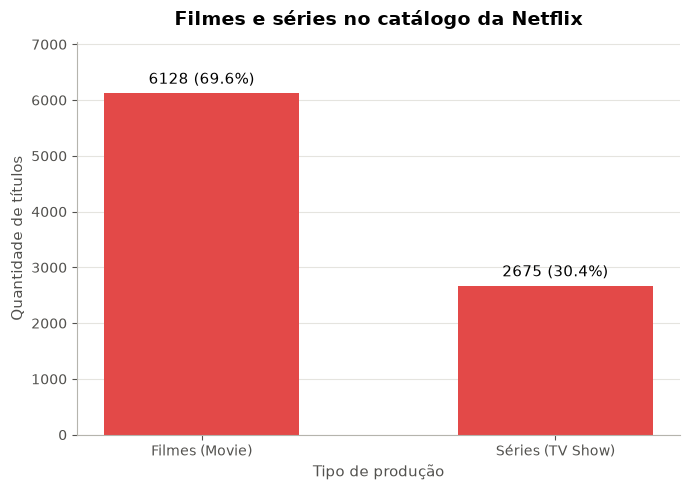

In [42]:
contagem_tipo = netflix_tratado['type'].value_counts().rename(
    index={'Movie': 'Filmes (Movie)', 'TV Show': 'Séries (TV Show)'}
)
percentual_tipo = contagem_tipo / contagem_tipo.sum() * 100

rotulos = []
for quantidade, percentual in zip(contagem_tipo.values, percentual_tipo.values):
    rotulos.append(f'{quantidade} ({percentual:.1f}%)')

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(contagem_tipo.index, contagem_tipo.values, color=COR_NETFLIX, width=0.55)
ax.bar_label(barras, labels=rotulos, padding=4, fontsize=11)

ax.set_title('Filmes e séries no catálogo da Netflix')
ax.set_xlabel('Tipo de produção')
ax.set_ylabel('Quantidade de títulos')
ax.set_ylim(0, contagem_tipo.max() * 1.15)   # espaço para os rótulos acima das barras
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

**Interpretação:** a diferença de altura entre as barras deixa evidente a predominância dos
**filmes**, cerca de 70% do catálogo, sobre as **séries**, cerca de 30%.

### 3.2 Top 10 países com mais produções

Barras **horizontais** facilitam a leitura dos nomes dos países. A ordem é invertida
(`iloc[::-1]`) para que o 1º colocado apareça no topo.

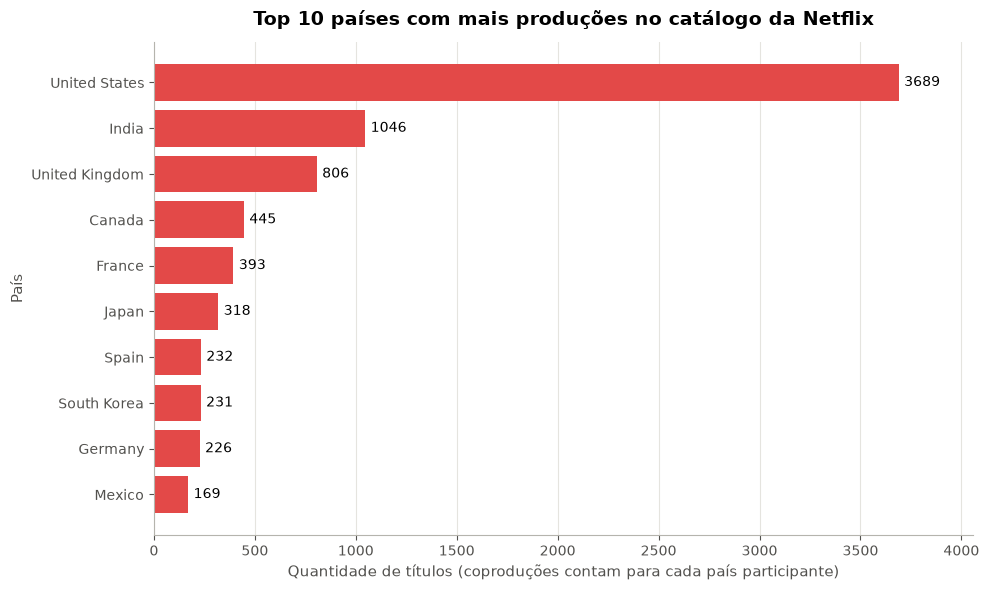

In [43]:
top10_grafico = top10_paises.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(top10_grafico.index, top10_grafico.values, color=COR_NETFLIX)
ax.bar_label(barras, padding=4)

ax.set_title('Top 10 países com mais produções no catálogo da Netflix')
ax.set_xlabel('Quantidade de títulos (coproduções contam para cada país participante)')
ax.set_ylabel('País')
ax.set_xlim(0, top10_grafico.max() * 1.1)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)

plt.tight_layout()
plt.show()

**Interpretação:** o gráfico mostra a **liderança isolada dos Estados Unidos**: a barra é mais de
três vezes maior que a da Índia, a 2ª colocada. Depois do Reino Unido, as diferenças entre os
demais países são bem menores. Espanha, Coreia do Sul e Alemanha, por exemplo, têm valores quase
iguais, entre 226 e 232 títulos.

### 3.3 Quantidade de títulos por ano de lançamento

Foi usado um **gráfico de barras por ano**, e não de linha, porque alguns anos não têm nenhum
título. Uma linha ligaria esses anos vazios como se houvesse valores entre eles.

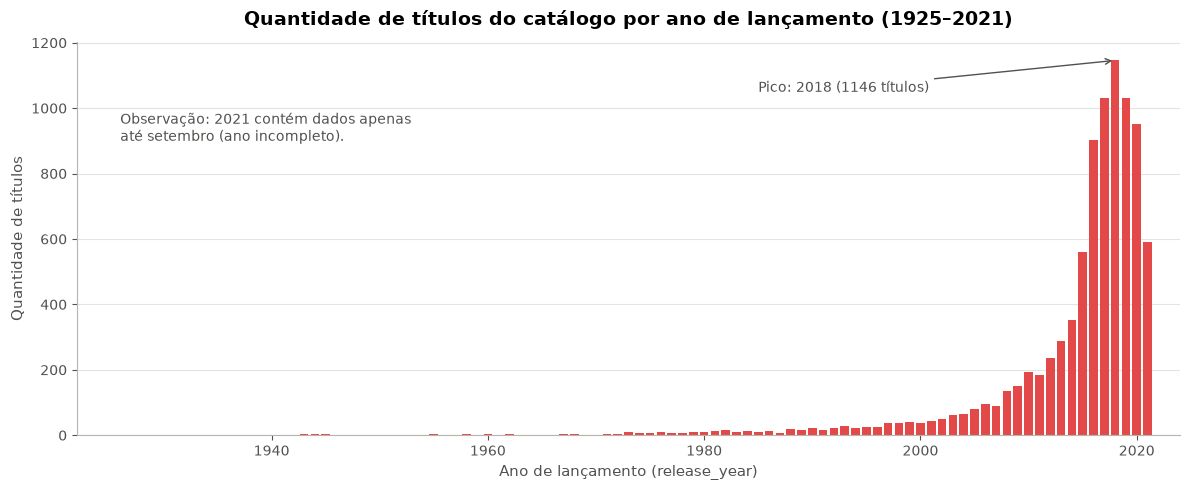

In [44]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(lancamentos_por_ano.index, lancamentos_por_ano.values, color=COR_NETFLIX, width=0.8)

# Destaques: ano de pico e ano incompleto
ano_pico = lancamentos_por_ano.idxmax()
ax.annotate(f'Pico: {ano_pico} ({lancamentos_por_ano.max()} títulos)',
            xy=(ano_pico, lancamentos_por_ano.max()), xytext=(1985, 1050),
            arrowprops={'arrowstyle': '->', 'color': '#52514e'}, color='#52514e')
ax.text(1926, 900, 'Observação: 2021 contém dados apenas\naté setembro (ano incompleto).', color='#52514e')

ax.set_title('Quantidade de títulos do catálogo por ano de lançamento (1925–2021)')
ax.set_xlabel('Ano de lançamento (release_year)')
ax.set_ylabel('Quantidade de títulos')
ax.set_xlim(1922, 2024)
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

**Interpretação:** praticamente todo o catálogo está concentrado no lado direito do gráfico. Até
os anos 1990 as barras são quase invisíveis, o crescimento se acelera a partir de 2015, e o pico
ocorre em **2018**. A queda em 2020 e 2021 não indica necessariamente menos produções, porque 2021
está incompleto e títulos recentes ainda podem não ter chegado ao catálogo.

### 3.4 Gráfico de livre escolha: ano de lançamento × ano de inclusão no catálogo

**Motivação:** este gráfico mostra visualmente a diferença entre `release_year` e `date_added`.
Para cada ano de 2008 a 2021, período em que há inclusões registradas, comparamos:

- quantos títulos do catálogo foram **lançados** naquele ano (`release_year`);
- quantos títulos **entraram no catálogo** naquele ano (`ano_adicao`).

As duas linhas usam cores **e** estilos diferentes (contínua × tracejada), para que sejam
distinguíveis também em impressão em preto e branco.

In [45]:
lancados = lancamentos_por_ano.loc[2008:2021]
incluidos = netflix_tratado['ano_adicao'].value_counts().sort_index()

comparacao = pd.DataFrame({'lançados no ano': lancados, 'incluídos no catálogo no ano': incluidos})
comparacao

,lançados no ano,incluídos no catálogo no ano
2008,136,2
2009,152,2
2010,193,1
2011,185,13
2012,237,3
2013,288,11
2014,351,24
2015,560,82
2016,902,429
2017,1032,1188


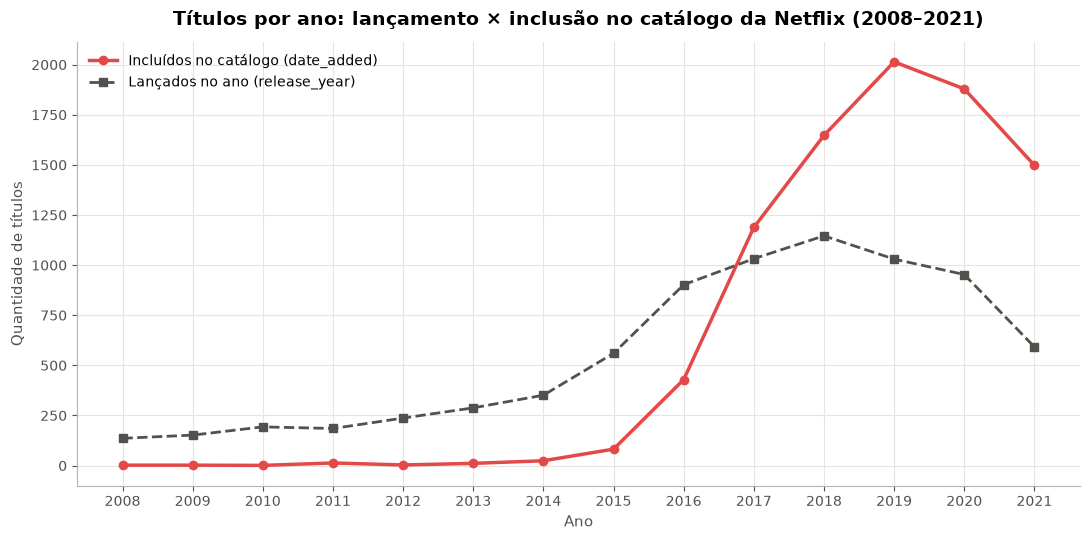

In [46]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(comparacao.index, comparacao['incluídos no catálogo no ano'], color=COR_NETFLIX,
        linewidth=2.5, marker='o', label='Incluídos no catálogo (date_added)')
ax.plot(comparacao.index, comparacao['lançados no ano'], color='#52514e',
        linewidth=2, linestyle='--', marker='s', label='Lançados no ano (release_year)')

ax.set_title('Títulos por ano: lançamento × inclusão no catálogo da Netflix (2008–2021)')
ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de títulos')
ax.set_xticks(range(2008, 2022))
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

**Interpretação:**

- Até **2016**, a linha tracejada (lançamentos) fica **acima** da vermelha (inclusões). Muitos
  títulos lançados nesses anos estão no catálogo, mas **entraram nele em anos posteriores**.
- De **2017** em diante, a situação se inverte, e as inclusões passam a superar os lançamentos de
  cada ano. O pico de inclusões ocorre em **2019 (2.014 títulos)**, um ano depois do pico de
  lançamentos (2018). Isso indica que a Netflix incluiu tanto títulos recentes quanto títulos de
  anos anteriores.
- O gráfico confirma que **`release_year` e `date_added` medem coisas diferentes**: um título
  lançado em 2015 pode ter sido incluído em 2019.
- **Cuidados de leitura:** 2021 está incompleto nas duas linhas. Além disso, a base é uma
  "fotografia" do catálogo em 2021. Títulos que entraram e saíram antes disso não aparecem, então
  as inclusões dos primeiros anos estão **subestimadas**.

---
<div align="center">

# PARTE II — Students Performance in Exams

</div>

Cada linha representa **um estudante**. A base não possui nome nem identificador; por isso,
o **índice da linha** do DataFrame será usado como identificação quando for necessário
apontar estudantes específicos.

| Coluna | Significado |
|---|---|
| `gender` | gênero (`female` / `male`) |
| `race/ethnicity` | grupo étnico, anonimizado como `group A` a `group E` |
| `parental level of education` | maior nível de escolaridade dos pais |
| `lunch` | tipo de alimentação escolar: `standard` (padrão) ou `free/reduced` (gratuita ou subsidiada) |
| `test preparation course` | curso preparatório: `completed` (concluído) ou `none` (não fez) |
| `math score` / `reading score` / `writing score` | notas de Matemática, Leitura e Escrita (0 a 100) |

---
# 4. Conhecendo e preparando os dados

## 4.1 Carga do CSV

In [47]:
alunos = pd.read_csv(ARQUIVO_ALUNOS)

print('Base de estudantes carregada com sucesso.')
print('Linhas:', alunos.shape[0], '| Colunas:', alunos.shape[1])
print('Quantidade esperada confere?', alunos.shape == (1000, 8))

Base de estudantes carregada com sucesso.
Linhas: 1000 | Colunas: 8
Quantidade esperada confere? True


**Conferência da carga.** O Kaggle informa **1.000 estudantes** e **8 colunas**. Também é
importante confirmar que as três notas foram lidas como **números inteiros** (`int64`), e não
como texto. Caso contrário, não seria possível calcular médias.

In [48]:
alunos[['math score', 'reading score', 'writing score']].dtypes

math score       int64
reading score    int64
writing score    int64
dtype: object

## 4.2 head() e tail()

In [49]:
alunos.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [50]:
alunos.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


**O que se observa:** cada linha descreve um estudante por meio de cinco atributos de texto
(gênero, grupo, escolaridade dos pais, alimentação e curso preparatório) e três notas
inteiras. Não há nome, matrícula ou outro identificador. O **índice da linha** (0 a 999) será a
única forma de apontar um estudante específico.

## 4.3 Quantidade de linhas e colunas

In [51]:
linhas, colunas = alunos.shape
print(f'A base possui {linhas} linhas (estudantes) e {colunas} colunas (atributos).')

A base possui 1000 linhas (estudantes) e 8 colunas (atributos).


## 4.4 Tipos das colunas

In [52]:
alunos.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

**Interpretação dos tipos:** as três notas são inteiras (`int64`), prontas para cálculos. As
outras cinco colunas são **categóricas em forma de texto** (`object` no pandas 2, `str` no
pandas 3). Elas servem para formar grupos de comparação, como gênero ou curso preparatório.
A célula abaixo lista os valores possíveis de cada uma, para conferir se há grafias diferentes
para a mesma categoria.

In [53]:
colunas_categoricas = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

for coluna in colunas_categoricas:
    print(f'{coluna:<28} {alunos[coluna].nunique()} valores: {sorted(alunos[coluna].unique())}')

gender                       2 valores: ['female', 'male']
race/ethnicity               5 valores: ['group A', 'group B', 'group C', 'group D', 'group E']
parental level of education  6 valores: ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']
lunch                        2 valores: ['free/reduced', 'standard']
test preparation course      2 valores: ['completed', 'none']


Todas as categorias estão escritas de forma consistente: não há variações de maiúsculas,
espaços extras ou erros de digitação.

## 4.5 Valores ausentes

In [54]:
alunos.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

**Nenhuma coluna tem valores ausentes.** Os 1.000 estudantes têm todas as informações
preenchidas, o que dispensa decisões sobre exclusão ou preenchimento de dados.

## 4.6 Registros duplicados

In [55]:
print('Linhas totalmente duplicadas:', alunos.duplicated().sum())

# Quantos estudantes repetem a mesma combinação de atributos (sem considerar as notas)?
print('Repetições considerando só as 5 colunas categóricas:', alunos.duplicated(subset=colunas_categoricas).sum())

Linhas totalmente duplicadas: 0
Repetições considerando só as 5 colunas categóricas: 789


**Interpretação:** não há linhas totalmente duplicadas. Como a base não tem identificador, uma
linha repetida não seria necessariamente um erro, porque dois estudantes diferentes poderiam
ter exatamente o mesmo perfil e as mesmas notas. Mas esse caso não ocorre.

Já a repetição de **perfis**, considerando só as colunas categóricas, é muito comum (789
linhas), e isso é esperado. Existem apenas 2 × 5 × 6 × 2 × 2 = 240 combinações possíveis de
gênero, grupo, escolaridade, alimentação e curso para 1.000 estudantes.

## 4.7 describe()

In [56]:
alunos.describe()

,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


In [57]:
alunos.describe(exclude='number')

,gender,race/ethnicity,parental level of education,lunch,test preparation course
count,1000,1000,1000,1000,1000
unique,2,5,6,2,2
top,female,group C,some college,standard,none
freq,518,319,226,645,642


**Informações relevantes obtidas com o `describe()`:**

1. **Matemática tem o pior desempenho:** é a disciplina com a **menor média (66,1)** e a única
   com nota mínima **0**. Leitura tem a maior média (69,2), e Escrita fica no meio (68,1).
2. **As notas são bastante dispersas:** o desvio padrão fica em torno de **15 pontos** nas três
   disciplinas. Em Matemática, metade dos estudantes está entre **57 e 77** (1º e 3º quartis), uma
   faixa de 20 pontos.
3. **Há estudantes nos dois extremos:** todas as disciplinas têm nota máxima 100, mas os mínimos
   são muito baixos (0 em Matemática, 17 em Leitura e 10 em Escrita). A investigação desses
   casos está no item 4.9.
4. **Composição dos grupos** (`describe` das colunas de texto): há um pouco mais de estudantes do
   gênero feminino (518); o grupo C é o mais numeroso (319); 645 estudantes têm alimentação
   padrão; e a maioria, **642 de 1.000, não fez o curso preparatório**.

## 4.8 Média e mediana das três notas

In [58]:
notas = ['math score', 'reading score', 'writing score']
nomes_disciplinas = {'math score': 'Matemática', 'reading score': 'Leitura', 'writing score': 'Escrita'}

pd.DataFrame({
    'média': alunos[notas].mean(),
    'mediana': alunos[notas].median(),
}).rename(index=nomes_disciplinas)

,média,mediana
Matemática,66.09,66.00
Leitura,69.17,70.00
Escrita,68.05,69.00


**Interpretação:** nas três disciplinas, a média e a mediana são próximas, com diferença de no
máximo 1 ponto. Assim, os poucos estudantes com notas muito baixas não distorcem muito a
média. A mediana de Leitura (70) indica que **metade dos estudantes tirou 70 ou mais** nessa
disciplina. Em Matemática, a mediana é 66.

## 4.9 Conferência dos valores e preparação da cópia de trabalho (`alunos_tratado`)

Antes das análises, verificamos se há notas fora da escala de 0 a 100 e investigamos os
estudantes com notas muito baixas.

In [59]:
fora_da_escala = (alunos[notas] < 0) | (alunos[notas] > 100)
print('Notas fora da escala 0–100:', fora_da_escala.sum().sum())

# Estudantes com alguma nota abaixo de 20
alunos[alunos[notas].min(axis=1) < 20]

Notas fora da escala 0–100: 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
327,male,group A,some college,free/reduced,none,28,23,19
596,male,group B,high school,free/reduced,none,30,24,15
787,female,group B,some college,standard,none,19,38,32
980,female,group B,high school,free/reduced,none,8,24,23


**Interpretação e decisão:** todas as notas estão dentro da escala. Os casos extremos, como a
estudante de índice 59, com nota 0 em Matemática, também têm notas baixas nas outras
disciplinas (17 e 10). O desempenho é **baixo de forma consistente**, e não parece um erro
isolado de digitação. Como a base não informa se uma nota 0 significa ausência na prova, esses
registros foram **mantidos**.

A base não precisou de correções. Mesmo assim, as análises são feitas em uma **cópia**
(`alunos_tratado`), porque a seção 5 cria novas colunas. Assim, o DataFrame original `alunos`
permanece exatamente como foi lido do arquivo.

In [60]:
alunos_tratado = alunos.copy()
print('Cópia criada:', alunos_tratado.shape)

Cópia criada: (1000, 8)


---
# 5. Análise do desempenho dos estudantes

Todas as questões usam a cópia `alunos_tratado`. As conclusões são **descritivas**: mostram
diferenças entre grupos nos dados, mas não permitem afirmar que uma característica **causa**
melhor ou pior desempenho.

### 5.1 Média das notas de Matemática, Leitura e Escrita

In [61]:
medias_disciplinas = alunos_tratado[notas].mean().rename(index=nomes_disciplinas)
medias_disciplinas.to_frame('média')

,média
Matemática,66.09
Leitura,69.17
Escrita,68.05


**Interpretação:** em média, os estudantes tiveram **66,09 em Matemática, 69,17 em Leitura e
68,05 em Escrita**. Os valores coincidem com os do item 4.8, como esperado. A diferença entre a
maior e a menor média é de cerca de 3 pontos.

### 5.2 Mediana de cada disciplina

In [62]:
medianas_disciplinas = alunos_tratado[notas].median().rename(index=nomes_disciplinas)
medianas_disciplinas.to_frame('mediana')

,mediana
Matemática,66.00
Leitura,70.00
Escrita,69.00


**Interpretação:** a mediana é o valor central depois de ordenar as notas: metade dos estudantes
ficou abaixo dele e metade acima. As medianas são **66 em Matemática, 70 em Leitura e 69 em
Escrita**, próximas das médias. A ordem entre as disciplinas é a mesma da média: Leitura >
Escrita > Matemática.

### 5.3 Qual disciplina possui a maior média?

`idxmax()` devolve o **rótulo** do maior valor, ou seja, o nome da disciplina, e não o valor.

In [63]:
print('Disciplina com maior média:', medias_disciplinas.idxmax(), f'({medias_disciplinas.max():.2f})')
print('Disciplina com menor média:', medias_disciplinas.idxmin(), f'({medias_disciplinas.min():.2f})')
print(f'Diferença entre elas: {medias_disciplinas.max() - medias_disciplinas.min():.2f} pontos')

Disciplina com maior média: Leitura (69.17)
Disciplina com menor média: Matemática (66.09)
Diferença entre elas: 3.08 pontos


**Interpretação:** **Leitura** tem a maior média (69,17). **Matemática** tem a menor (66,09),
3,08 pontos abaixo. Ou seja, os estudantes, em conjunto, tiveram mais dificuldade em
Matemática.

### 5.4 Criação da coluna `media_geral`

A `media_geral` de **cada estudante** é a média aritmética das suas três notas:

$$\text{media\_geral} = \frac{\text{Matemática} + \text{Leitura} + \text{Escrita}}{3}$$

Com `mean(axis=1)`, o pandas calcula a média **ao longo de cada linha**, ou seja, por estudante.
O padrão, `axis=0`, calcularia a média de cada coluna, ou seja, por disciplina, como no item 5.1.

In [64]:
alunos_tratado['media_geral'] = alunos_tratado[notas].mean(axis=1)

# Conferência: a mesma conta feita "à mão" deve dar exatamente o mesmo resultado
media_manual = (alunos_tratado['math score'] + alunos_tratado['reading score'] + alunos_tratado['writing score']) / 3
print('As duas formas de cálculo coincidem?', (alunos_tratado['media_geral'] - media_manual).abs().max() < 1e-9)

alunos_tratado[notas + ['media_geral']].head()

As duas formas de cálculo coincidem? True


,math score,reading score,writing score,media_geral
0,72,72,74,72.67
1,69,90,88,82.33
2,90,95,93,92.67
3,47,57,44,49.33
4,76,78,75,76.33


**Conferência pela primeira linha:** (72 + 72 + 74) / 3 = 218 / 3 = **72,67**, valor igual ao da
tabela.

> **Atenção:** `media_geral` é a média **de um estudante** nas três disciplinas. Ela é diferente
> da média **de uma disciplina** entre todos os estudantes (item 5.1). Por exemplo, a nota 66,09
> é a média de Matemática da turma, e não a média geral de alguém.

### 5.5 Os 10 estudantes com maior média geral

Como não há nomes, os estudantes são identificados pelo **índice da linha**. Ordenamos de forma
decrescente pela média geral.

**Critério de desempate:** quando dois estudantes têm a mesma média, fica à frente o de **menor
índice**, ou seja, o que aparece primeiro no arquivo. É isso que o `kind='stable'` garante: ele
mantém a ordem original entre os empatados. É um critério **neutro e reproduzível**, que dá
sempre o mesmo resultado, mas não tem significado de desempenho. Ele apenas permite apresentar
exatamente 10 estudantes.

In [65]:
ranking = alunos_tratado.sort_values('media_geral', ascending=False, kind='stable')
top10 = ranking.head(10)

top10[['gender', 'test preparation course'] + notas + ['media_geral']].rename_axis('id (índice)')

,gender,test preparation course,math score,reading score,writing score,media_geral
id (índice),,,,,,
458,female,none,100,100,100,100.00
916,male,completed,100,100,100,100.00
962,female,none,100,100,100,100.00
114,female,completed,99,100,100,99.67
179,female,completed,97,100,100,99.00
712,female,none,98,100,99,99.00
165,female,completed,96,100,100,98.67
625,male,completed,100,97,99,98.67
149,male,completed,100,100,93,97.67


**Conferência de empate na nota de corte:** algum estudante fora do top 10 tem a mesma média do
10º colocado?

In [66]:
nota_corte = top10['media_geral'].iloc[9]
empatados_no_corte = alunos_tratado[alunos_tratado['media_geral'] == nota_corte]
dentro_do_top10 = empatados_no_corte.index.isin(top10.index)

print(f'Média do 10º colocado (nota de corte): {nota_corte:.2f}')
print('Estudantes com essa mesma média      :', len(empatados_no_corte))
print('  dentro do top 10 (índices)         :', list(empatados_no_corte.index[dentro_do_top10]))
print('  fora do top 10 (índices)           :', list(empatados_no_corte.index[~dentro_do_top10]))

Média do 10º colocado (nota de corte): 97.67
Estudantes com essa mesma média      : 3
  dentro do top 10 (índices)         : [149, 685]
  fora do top 10 (índices)           : [903]


**Interpretação:**

- **Três estudantes**, de índices 458, 916 e 962, tiraram **100 nas três disciplinas** e empatam
  em 1º lugar.
- **Atenção ao empate na nota de corte:** três estudantes têm média **97,67**. Pelo critério de
  desempate, os de índices 149 e 685 ocupam o 9º e o 10º lugares, e o **estudante 903 fica em
  11º com exatamente a mesma média**. Ele está empatado com o 10º colocado e só fica fora da
  lista por causa do critério de desempate, e não por ter desempenho inferior.
- Entre os 10 primeiros, 7 são do gênero feminino e 7 concluíram o curso preparatório. Com tão
  poucos estudantes, porém, essas proporções servem só como observação, e não como conclusão
  sobre os grupos.

### 5.6 Percentual de aprovados (média geral ≥ 70)

O critério é **maior ou igual** a 70: um estudante com média exatamente 70 está aprovado.

In [67]:
alunos_tratado['aprovado'] = alunos_tratado['media_geral'] >= 70

aprovados = alunos_tratado['aprovado'].sum()        # True conta como 1, False como 0
percentual_aprovados = alunos_tratado['aprovado'].mean() * 100

print(f'Aprovados  : {aprovados} de {len(alunos_tratado)} estudantes')
print(f'Percentual : {percentual_aprovados:.1f}%')
print(f'Reprovados : {len(alunos_tratado) - aprovados} ({100 - percentual_aprovados:.1f}%)')

Aprovados  : 459 de 1000 estudantes
Percentual : 45.9%
Reprovados : 541 (54.1%)


**Conferências do cálculo:**

1. Média ≥ 70 equivale a **soma das três notas ≥ 210**. Como a soma é um número inteiro, essa
   segunda forma não sofre com arredondamentos de casas decimais e deve dar o mesmo total.
2. Quantos estudantes estão **exatamente** na nota de corte? Eles mostram por que o sinal `≥`
   é importante.

In [68]:
soma_notas = alunos_tratado[notas].sum(axis=1)
print('Aprovados pela soma (>= 210):', (soma_notas >= 210).sum())
print('Estudantes com média exatamente 70:', (alunos_tratado['media_geral'] == 70).sum())
print('Aprovados se o critério fosse "> 70":', (alunos_tratado['media_geral'] > 70).sum())

Aprovados pela soma (>= 210): 459
Estudantes com média exatamente 70: 12
Aprovados se o critério fosse "> 70": 447


**Interpretação:** **459 estudantes (45,9%) foram aprovados** e 541 (54,1%) reprovados, ou seja,
**menos da metade** atingiu a média 70. A conferência pela soma das notas confirma o total. Doze
estudantes têm média **exatamente 70** e só são aprovados porque o critério é "maior **ou
igual**". Com "maior que 70", seriam 447 aprovados (44,7%).

### 5.7 Comparação da média geral por gênero

Usamos `groupby()` para separar os estudantes por gênero e calcular as estatísticas de cada
grupo. A média de `aprovado` (True/False) é a proporção de aprovados.

In [69]:
por_genero = pd.DataFrame({
    'estudantes': alunos_tratado.groupby('gender')['media_geral'].count(),
    'média geral': alunos_tratado.groupby('gender')['media_geral'].mean(),
    'mediana': alunos_tratado.groupby('gender')['media_geral'].median(),
    'aprovados (%)': alunos_tratado.groupby('gender')['aprovado'].mean() * 100,
})
por_genero

,estudantes,média geral,mediana,aprovados (%)
gender,,,,
female,518,69.57,70.33,51.74
male,482,65.84,66.33,39.63


In [70]:
diferenca_genero = por_genero.loc['female', 'média geral'] - por_genero.loc['male', 'média geral']
print(f'Diferença (feminino - masculino): {diferenca_genero:.2f} pontos')

Diferença (feminino - masculino): 3.73 pontos


**Interpretação:** o grupo **feminino** tem média geral maior, **69,57** contra **65,84**, uma
diferença de 3,73 pontos. A taxa de aprovação também é maior: **51,7%** contra **39,6%**. Os dois
grupos têm tamanhos parecidos (518 e 482), o que torna a comparação equilibrada. Como mostra o
gráfico 6.5, porém, essa vantagem **não se repete em todas as disciplinas**.

### 5.8 Com curso preparatório × sem curso preparatório

In [71]:
por_curso = pd.DataFrame({
    'estudantes': alunos_tratado.groupby('test preparation course')['media_geral'].count(),
    'média geral': alunos_tratado.groupby('test preparation course')['media_geral'].mean(),
    'mediana': alunos_tratado.groupby('test preparation course')['media_geral'].median(),
    'aprovados (%)': alunos_tratado.groupby('test preparation course')['aprovado'].mean() * 100,
})
por_curso

,estudantes,média geral,mediana,aprovados (%)
test preparation course,,,,
completed,358,72.67,73.50,60.89
none,642,65.04,65.33,37.54


In [72]:
diferenca_curso = por_curso.loc['completed', 'média geral'] - por_curso.loc['none', 'média geral']
print(f'Diferença (concluiu - não fez): {diferenca_curso:.2f} pontos')

Diferença (concluiu - não fez): 7.63 pontos


**Interpretação:** quem **concluiu o curso** tem média geral de **72,67**, contra **65,04** de
quem não fez, uma diferença de **7,63 pontos**. A aprovação sobe de **37,5%** para **60,9%**. É a
maior diferença observada até aqui.

**Cuidado com a interpretação causal:** a base mostra uma **associação**, e não prova que o curso
**causou** a melhora. Os estudantes não foram sorteados para fazer o curso. É possível que quem
escolheu fazê-lo já fosse mais motivado ou tivesse mais apoio em casa, e essas características
não estão na base.

### 5.9 Média geral por nível de escolaridade dos pais

Os níveis de escolaridade têm uma **ordem natural**. Por isso, a tabela é organizada do menor
para o maior nível com `reindex()`, e não em ordem alfabética.

In [73]:
ordem_escolaridade = ['some high school', 'high school', 'some college',
                      "associate's degree", "bachelor's degree", "master's degree"]
traducao_escolaridade = {
    'some high school': 'Ensino médio incompleto',
    'high school': 'Ensino médio completo',
    'some college': 'Superior incompleto',
    "associate's degree": 'Superior de curta duração (associate)',
    "bachelor's degree": 'Bacharelado',
    "master's degree": 'Mestrado',
}

por_escolaridade = pd.DataFrame({
    'estudantes': alunos_tratado.groupby('parental level of education')['media_geral'].count(),
    'média geral': alunos_tratado.groupby('parental level of education')['media_geral'].mean(),
    'aprovados (%)': alunos_tratado.groupby('parental level of education')['aprovado'].mean() * 100,
}).reindex(ordem_escolaridade)

por_escolaridade.rename(index=traducao_escolaridade)

,estudantes,média geral,aprovados (%)
parental level of education,,,
Ensino médio incompleto,179,65.11,41.34
Ensino médio completo,196,63.10,33.16
Superior incompleto,226,68.48,47.79
Superior de curta duração (associate),222,69.57,49.55
Bacharelado,118,71.92,55.93
Mestrado,59,73.60,61.02


**Interpretação:**

- Os estudantes cujos pais têm **mestrado** têm a maior média geral (**73,60**) e a maior
  aprovação (61,0%). Em seguida vêm os de pais com **bacharelado** (71,92).
- A menor média é a do grupo de pais com **ensino médio completo** (**63,10**), 10,5 pontos
  abaixo do grupo de mestrado.
- Há uma **tendência geral de aumento** da média com a escolaridade dos pais, mas ela **não é
  perfeitamente crescente**: o grupo de pais com ensino médio **incompleto** (65,11) tem média
  maior que o de ensino médio **completo** (63,10).
- O grupo de mestrado é o menor (59 estudantes), então sua média é mais sensível a poucos
  casos. Assim como no curso preparatório, trata-se de associação: a escolaridade dos pais
  pode estar ligada a outros fatores, como renda, que a base não mede diretamente.

### 5.10 Grupo (race/ethnicity) com maior média geral

In [74]:
por_grupo = pd.DataFrame({
    'estudantes': alunos_tratado.groupby('race/ethnicity')['media_geral'].count(),
    'média geral': alunos_tratado.groupby('race/ethnicity')['media_geral'].mean(),
    'aprovados (%)': alunos_tratado.groupby('race/ethnicity')['aprovado'].mean() * 100,
}).sort_values('média geral', ascending=False)

print('Grupo com maior média geral:', por_grupo['média geral'].idxmax())
por_grupo

Grupo com maior média geral: group E


,estudantes,média geral,aprovados (%)
race/ethnicity,,,
group E,140,72.75,62.14
group D,262,69.18,50.38
group C,319,67.13,44.51
group B,190,65.47,38.42
group A,89,62.99,28.09


**Interpretação:** o **grupo E** tem a maior média geral (**72,75**) e a maior aprovação (62,1%).
O grupo A tem a menor média (62,99), quase 10 pontos abaixo. Curiosamente, as médias crescem na
mesma ordem das letras (A < B < C < D < E).

**Limitação importante:** os grupos foram **anonimizados** pelos autores da base, e a base não
informa o que cada letra representa. Por isso, não é possível interpretar o resultado em termos
de grupos reais da população. Os grupos também têm tamanhos bem diferentes, de 89 estudantes no
grupo A a 319 no grupo C.

---
# 6. Visualização dos dados

Os gráficos seguem o padrão visual da seção 0, com o **azul** como cor da base de estudantes.
Nos gráficos de média, o eixo vertical vai de **0 a 100**, a escala completa das notas, para não
exagerar visualmente diferenças pequenas. A linha tracejada marca a **nota 70**, o critério de
aprovação.

### 6.1 Distribuição das notas de Matemática

O **histograma** agrupa as notas em faixas de 5 pontos (0–5, 5–10, …) e mostra quantos
estudantes há em cada faixa.

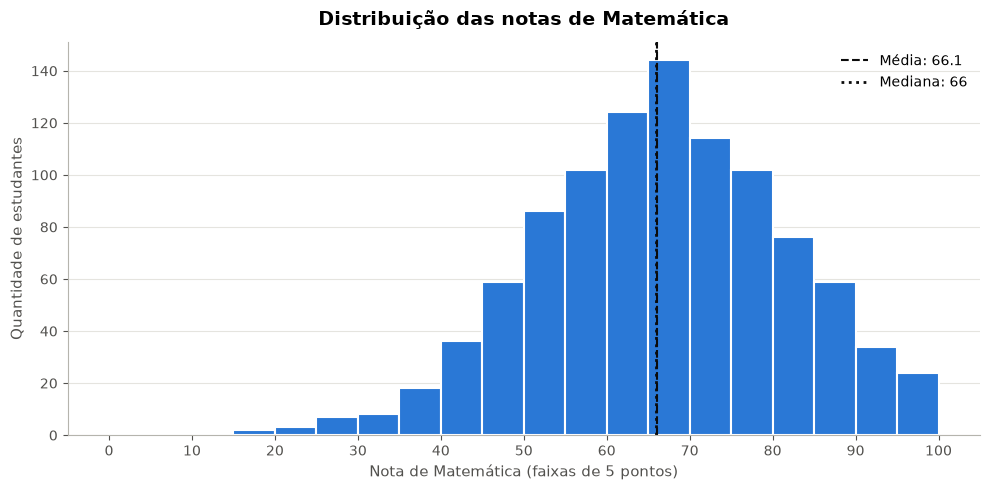

In [75]:
nota_matematica = alunos_tratado['math score']

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(nota_matematica, bins=range(0, 105, 5), color=COR_ALUNOS, edgecolor='white', linewidth=1.5)
ax.axvline(nota_matematica.mean(), color='#0b0b0b', linestyle='--', linewidth=1.5,
           label=f'Média: {nota_matematica.mean():.1f}')
ax.axvline(nota_matematica.median(), color='#0b0b0b', linestyle=':', linewidth=2,
           label=f'Mediana: {nota_matematica.median():.0f}')

ax.set_title('Distribuição das notas de Matemática')
ax.set_xlabel('Nota de Matemática (faixas de 5 pontos)')
ax.set_ylabel('Quantidade de estudantes')
ax.set_xticks(range(0, 101, 10))
ax.grid(axis='x', visible=False)
ax.legend()

plt.tight_layout()
plt.show()

In [76]:
print(f'Estudantes com nota entre 50 e 80: {nota_matematica.between(50, 80).mean() * 100:.1f}%')
print('Estudantes com nota abaixo de 40 :', (nota_matematica < 40).sum())
print(f'Estudantes com nota 70 ou mais   : {(nota_matematica >= 70).mean() * 100:.1f}%')
print('Estudantes com nota 100          :', (nota_matematica == 100).sum())

Estudantes com nota entre 50 e 80: 68.9%
Estudantes com nota abaixo de 40 : 40
Estudantes com nota 70 ou mais   : 40.9%
Estudantes com nota 100          : 7


**Interpretação:** as notas de Matemática se concentram na região central. A faixa mais
frequente é a de **65 a 70 pontos**, e **68,9% dos estudantes** tiraram entre 50 e 80. As
extremidades têm poucos estudantes: **40 tiraram menos de 40**, com casos isolados chegando a
0, e apenas **7 tiraram 100**. Média (66,1) e mediana (66) quase se sobrepõem no centro.
Apenas **40,9%** atingiram 70 ou mais em Matemática, o que ajuda a explicar a baixa taxa de
aprovação geral.

### 6.2 Comparação das médias de Matemática, Leitura e Escrita

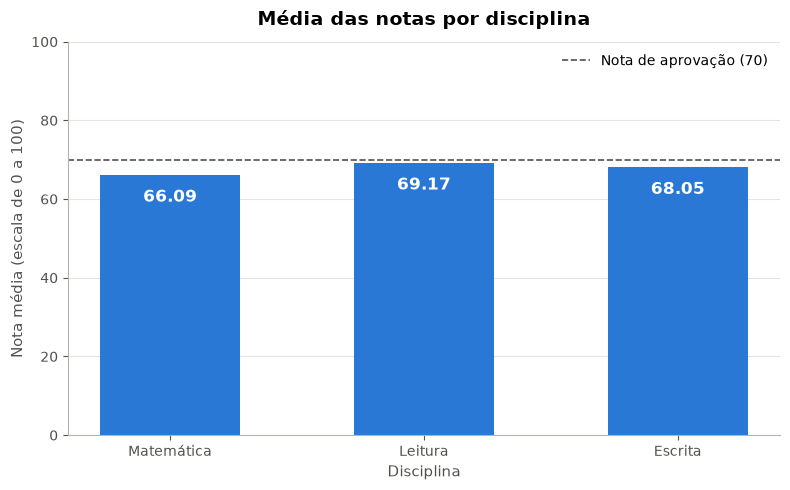

In [77]:
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(medias_disciplinas.index, medias_disciplinas.values, color=COR_ALUNOS, width=0.55)
ax.bar_label(barras, fmt='%.2f', padding=-22, color='white', fontsize=12, fontweight='bold')   # rótulo dentro da barra
ax.axhline(70, color='#52514e', linestyle='--', linewidth=1.2, label='Nota de aprovação (70)')

ax.set_title('Média das notas por disciplina')
ax.set_xlabel('Disciplina')
ax.set_ylabel('Nota média (escala de 0 a 100)')
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretação:** as três médias são próximas: **Leitura (69,17) > Escrita (68,05) >
Matemática (66,09)**. Na escala completa de 0 a 100, a diferença de cerca de 3 pontos entre a
maior e a menor média é **pequena**. As três médias também ficam **logo abaixo da nota 70**, o
que é coerente com a aprovação geral de 45,9%.

### 6.3 Média geral por gênero

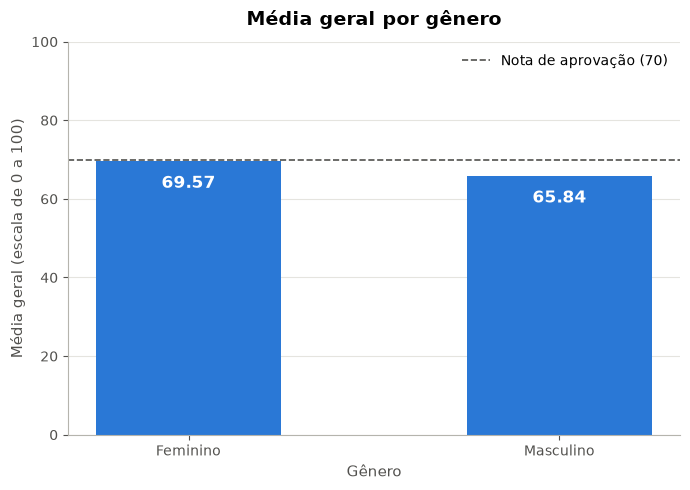

In [78]:
media_por_genero = por_genero['média geral'].rename(index={'female': 'Feminino', 'male': 'Masculino'})

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(media_por_genero.index, media_por_genero.values, color=COR_ALUNOS, width=0.5)
ax.bar_label(barras, fmt='%.2f', padding=-22, color='white', fontsize=12, fontweight='bold')   # rótulo dentro da barra
ax.axhline(70, color='#52514e', linestyle='--', linewidth=1.2, label='Nota de aprovação (70)')

ax.set_title('Média geral por gênero')
ax.set_xlabel('Gênero')
ax.set_ylabel('Média geral (escala de 0 a 100)')
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretação:** o grupo feminino tem média geral **3,73 pontos maior** (69,57 × 65,84). Um
detalhe importante: **as duas médias ficam abaixo de 70**, e a do grupo feminino fica muito perto
da linha. Ainda assim, mais da metade das estudantes (51,7%) foi aprovada, porque a média do
grupo não é igual à situação individual de cada estudante.

### 6.4 Média dos estudantes com e sem curso preparatório

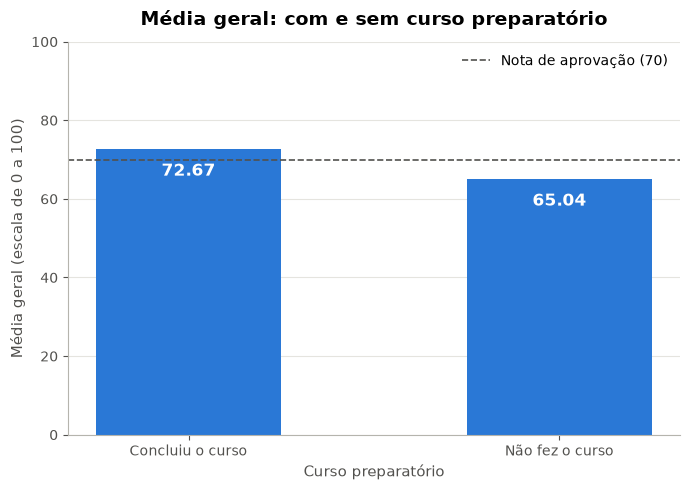

In [79]:
media_por_curso = por_curso['média geral'].rename(index={'completed': 'Concluiu o curso', 'none': 'Não fez o curso'})

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(media_por_curso.index, media_por_curso.values, color=COR_ALUNOS, width=0.5)
ax.bar_label(barras, fmt='%.2f', padding=-22, color='white', fontsize=12, fontweight='bold')   # rótulo dentro da barra
ax.axhline(70, color='#52514e', linestyle='--', linewidth=1.2, label='Nota de aprovação (70)')

ax.set_title('Média geral: com e sem curso preparatório')
ax.set_xlabel('Curso preparatório')
ax.set_ylabel('Média geral (escala de 0 a 100)')
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretação:** é a comparação com **maior diferença** entre os gráficos: **7,63 pontos**
(72,67 × 65,04). É também a única em que um grupo fica **acima** da linha de aprovação e o
outro **abaixo**. Como discutido na questão 5.8, a diferença indica associação, e não comprova
que o curso tenha causado o melhor desempenho.

### 6.5 Gráfico de livre escolha: desempenho por disciplina e gênero

**Motivação:** a questão 5.7 mostrou que o grupo feminino tem média geral maior. Mas essa
vantagem aparece em **todas** as disciplinas? Para responder, comparamos as médias de cada
disciplina separadamente por gênero, em um gráfico de **barras agrupadas**.

In [80]:
medias_disciplina_genero = alunos_tratado.groupby('gender')[notas].mean().rename(columns=nomes_disciplinas)
medias_disciplina_genero

,Matemática,Leitura,Escrita
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


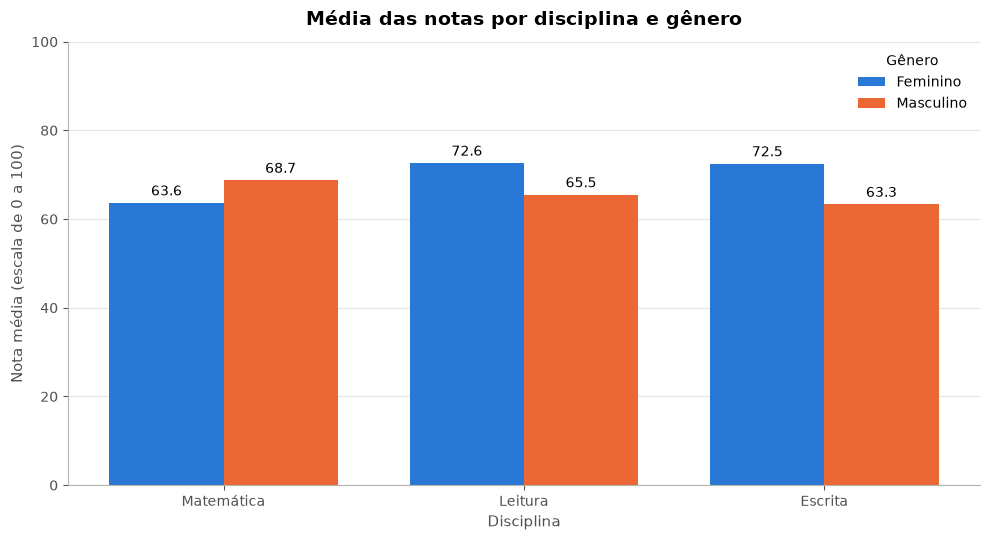

In [81]:
disciplinas = list(medias_disciplina_genero.columns)
posicoes = range(len(disciplinas))
largura = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
barras_f = ax.bar([p - largura / 2 for p in posicoes], medias_disciplina_genero.loc['female'],
                  width=largura, color=CORES[0], label='Feminino')
barras_m = ax.bar([p + largura / 2 for p in posicoes], medias_disciplina_genero.loc['male'],
                  width=largura, color=CORES[1], label='Masculino')
ax.bar_label(barras_f, fmt='%.1f', padding=3)
ax.bar_label(barras_m, fmt='%.1f', padding=3)

ax.set_title('Média das notas por disciplina e gênero')
ax.set_xlabel('Disciplina')
ax.set_ylabel('Nota média (escala de 0 a 100)')
ax.set_xticks(list(posicoes))
ax.set_xticklabels(disciplinas)
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(title='Gênero', loc='upper right')

plt.tight_layout()
plt.show()

In [82]:
diferencas = medias_disciplina_genero.loc['female'] - medias_disciplina_genero.loc['male']
diferencas.to_frame('diferença (feminino - masculino)')

,diferença (feminino - masculino)
Matemática,-5.10
Leitura,7.14
Escrita,9.16


**Interpretação (descoberta):** a vantagem feminina **não é uniforme**, e há uma **inversão**
entre as disciplinas:

- em **Matemática**, o grupo **masculino** tem média maior, com **5,1 pontos** a mais (68,7 × 63,6);
- em **Leitura** e **Escrita**, o grupo **feminino** tem média maior, com **7,1** e **9,2 pontos**
  a mais, respectivamente.

Portanto, a média geral maior do grupo feminino (questão 5.7) vem de Leitura e Escrita, e
**esconde** o fato de que, em Matemática, a vantagem é do grupo masculino. Esse exemplo mostra
que uma média agregada pode ocultar diferenças importantes. Mais uma vez, o resultado é
descritivo: a base não traz informações que expliquem a origem dessas diferenças.

---
<div align="center">

# PARTE III — Investigação livre e conclusões

</div>

---
# 7. Investigação livre

Quatro perguntas próprias, duas para cada base. Cada investigação segue o roteiro:
**pergunta → justificativa → seleção e tratamento dos dados → análise com Pandas → gráfico →
resultados → conclusão**.

| # | Base | Pergunta |
|---|---|---|
| 7.1 | Netflix | Como a proporção de filmes e séries mudou entre as décadas? |
| 7.2 | Netflix | Quais gêneros de filmes ganharam ou perderam participação entre as décadas? |
| 7.3 | Estudantes | A diferença de desempenho entre os tipos de alimentação é semelhante nas três disciplinas? |
| 7.4 | Estudantes | A associação entre curso preparatório e aprovação muda conforme o tipo de alimentação? |

## 7.1 Netflix — Como a proporção de filmes e séries mudou entre as décadas?

**Justificativa:** a questão 2.1 mostrou que o catálogo tem cerca de 70% de filmes e 30% de
séries **no total**. Um total pode esconder mudanças ao longo do tempo. Esta investigação verifica
se essa proporção é parecida entre títulos antigos e recentes.

**Seleção e tratamento:**

- usamos `netflix_tratado`, sem as quase-duplicatas;
- a década vem de `release_year`, o **ano de lançamento**, com a mesma regra da questão 2.6;
- calculamos, **dentro de cada década**, o percentual de filmes e de séries. O denominador é o
  total de títulos daquela década;
- como algumas décadas têm pouquíssimos títulos (a de 1920 tem só um), **o tamanho da amostra
  aparece ao lado de cada percentual**. No gráfico, entram apenas as décadas com **pelo menos
  100 títulos**, para evitar conclusões baseadas em poucos casos.

In [83]:
netflix_tratado['decada'] = (netflix_tratado['release_year'] // 10) * 10

# crosstab: tabela que conta quantos títulos há em cada combinação de década e tipo
tipo_por_decada = pd.crosstab(netflix_tratado['decada'], netflix_tratado['type'])
tipo_por_decada['total'] = tipo_por_decada['Movie'] + tipo_por_decada['TV Show']
tipo_por_decada['% filmes'] = tipo_por_decada['Movie'] / tipo_por_decada['total'] * 100
tipo_por_decada['% séries'] = tipo_por_decada['TV Show'] / tipo_por_decada['total'] * 100

tipo_por_decada

type,Movie,TV Show,total,% filmes,% séries
decada,,,,,
1920,0,1,1,0.00,100.00
1940,13,2,15,86.67,13.33
1950,11,0,11,100.00,0.00
1960,23,2,25,92.00,8.00
1970,66,4,70,94.29,5.71
1980,121,7,128,94.53,5.47
1990,241,33,274,87.96,12.04
2000,677,133,810,83.58,16.42
2010,4182,1742,5924,70.59,29.41


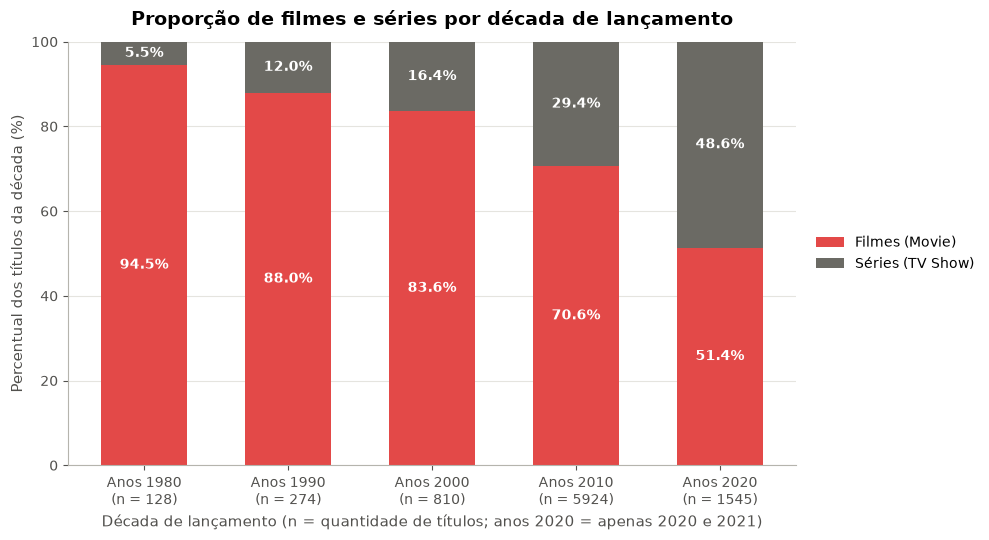

In [84]:
LIMITE_AMOSTRA = 100
decadas_grafico = tipo_por_decada[tipo_por_decada['total'] >= LIMITE_AMOSTRA]

rotulos_decadas = []
for decada, total in zip(decadas_grafico.index, decadas_grafico['total']):
    rotulos_decadas.append(f'Anos {decada}\n(n = {total})')

fig, ax = plt.subplots(figsize=(10, 5.5))
barras_filmes = ax.bar(rotulos_decadas, decadas_grafico['% filmes'], color=COR_NETFLIX, width=0.6,
                       label='Filmes (Movie)')
barras_series = ax.bar(rotulos_decadas, decadas_grafico['% séries'], bottom=decadas_grafico['% filmes'],
                       color='#6b6a64', width=0.6, label='Séries (TV Show)')
ax.bar_label(barras_filmes, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')
ax.bar_label(barras_series, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

ax.set_title('Proporção de filmes e séries por década de lançamento')
ax.set_xlabel('Década de lançamento (n = quantidade de títulos; anos 2020 = apenas 2020 e 2021)')
ax.set_ylabel('Percentual dos títulos da década (%)')
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))

plt.tight_layout()
plt.show()

**Resultados:**

| Década | Títulos | % séries |
|---|---|---|
| 1980 | 128 | 5,5% |
| 1990 | 274 | 12,0% |
| 2000 | 810 | 16,4% |
| 2010 | 5.924 | 29,4% |
| 2020 (2020–2021) | 1.545 | **48,6%** |

As décadas anteriores a 1980 têm de 1 a 70 títulos cada. Nelas, as séries são raras, mas os
percentuais oscilam muito por causa das amostras pequenas. Na de 1920, o único título é uma
série, o que dá "100% de séries" sem nenhum significado.

**Conclusão:** entre as décadas com amostra suficiente, a **participação das séries cresce de
forma contínua**: de cerca de 1 em cada 20 títulos nos anos 1980 para **quase metade** dos
títulos lançados em 2020–2021. Ou seja, o perfil de 70% de filmes visto na questão 2.1 vale
para o catálogo como um todo, mas não para os títulos mais recentes.

**Cuidados na interpretação:**

1. A base é o **catálogo da Netflix em 2021**, e não toda a produção mundial. O resultado mostra
   quais títulos de cada época estão disponíveis, e não quantos filmes e séries foram produzidos
   em cada época.
2. Nas séries, `release_year` pode registrar o ano da **temporada mais recente**. O item 1.9
   mostrou 12 séries incluídas no catálogo antes do próprio "ano de lançamento". Se isso for
   comum, parte das séries antigas aparece como recente, o que **inflaria** a participação das
   séries nas últimas décadas.
3. A década de 2020 tem só dois anos, e 2021 está incompleto.

## 7.2 Netflix — Quais gêneros de filmes ganharam ou perderam participação entre as décadas?

**Justificativa:** a questão 2.5 mostrou que o catálogo é dominado por títulos recentes. Esta
investigação verifica se o **tipo de conteúdo** também mudou, comparando a presença dos
principais gêneros em títulos de épocas diferentes.

**Seleção e tratamento dos dados:**

1. **`listed_in` tem até 3 categorias por título**, separadas por vírgula. Assim como países e
   diretores, as categorias são separadas com `str.split(',')`, `explode()` e `str.strip()`.
2. **Denominador:** a participação de um gênero em um período é o **percentual de filmes do
   período que têm aquele gênero**. Como um filme pode ter mais de uma categoria, os
   percentuais de um período **somam mais de 100%**, e isso é esperado.
3. **Apenas filmes:** a Netflix usa **categorias diferentes** para filmes e séries, como
   `Dramas` × `TV Dramas` e `Comedies` × `TV Comedies`. Como a proporção de séries muda muito
   entre as décadas (investigação 7.1), misturar os dois tipos criaria uma tendência falsa. A
   célula de conferência abaixo mostra esse problema.
4. **Recorte temporal: 2000 a 2021.** Antes de 2000 há apenas 475 filmes, espalhados por seis
   décadas, o que é pouco para comparar gêneros década a década. A comparação principal é entre
   as **duas décadas completas, 2000–2009 e 2010–2019**. O período 2020–2021, incompleto, aparece
   como complemento.

In [85]:
# Período de lançamento (somente títulos lançados a partir de 2000)
netflix_tratado['periodo'] = None
netflix_tratado.loc[netflix_tratado['release_year'].between(2000, 2009), 'periodo'] = '2000–2009'
netflix_tratado.loc[netflix_tratado['release_year'].between(2010, 2019), 'periodo'] = '2010–2019'
netflix_tratado.loc[netflix_tratado['release_year'] >= 2020, 'periodo'] = '2020–2021'

titulos_periodo = netflix_tratado[netflix_tratado['periodo'].notna()]

# Uma linha para cada combinação título-gênero.
# reset_index evita índices repetidos depois do explode
generos = titulos_periodo.assign(genero=titulos_periodo['listed_in'].str.split(',')).explode('genero')
generos = generos.reset_index(drop=True)
generos['genero'] = generos['genero'].str.strip()

print('Títulos lançados de 2000 a 2021:', len(titulos_periodo))
print('Linhas título-gênero           :', len(generos))
print(f'Média de gêneros por título    : {len(generos) / len(titulos_periodo):.2f}')

Títulos lançados de 2000 a 2021: 8279
Linhas título-gênero           : 18129
Média de gêneros por título    : 2.19


**Conferência: por que analisar só filmes?** A célula abaixo calcula a participação da
categoria `Dramas` de duas formas: considerando **todos os títulos** e considerando **somente
filmes**.

In [86]:
total_titulos = titulos_periodo['periodo'].value_counts().sort_index()
total_filmes = titulos_periodo[titulos_periodo['type'] == 'Movie']['periodo'].value_counts().sort_index()

drama = generos[generos['genero'] == 'Dramas']
pd.DataFrame({
    '% de todos os títulos': drama['periodo'].value_counts() / total_titulos * 100,
    '% dos filmes': drama[drama['type'] == 'Movie']['periodo'].value_counts() / total_filmes * 100,
})

,% de todos os títulos,% dos filmes
periodo,,
2000–2009,33.70,40.32
2010–2019,27.92,39.55
2020–2021,18.58,36.15


Considerando todos os títulos, `Dramas` parece **cair pela metade** (de 33,7% para 18,6%). Entre
os filmes, porém, a participação fica **quase estável** (de 40,3% para 36,1%). A queda aparente é
um efeito do denominador: como há cada vez mais séries no catálogo, e elas são classificadas como
`TV Dramas`, a fatia de `Dramas` no total diminui. Isso confirma a decisão de comparar
**somente filmes**.

In [87]:
generos_filmes = generos[generos['type'] == 'Movie']

# 10 gêneros mais frequentes entre os filmes de 2000 a 2021
principais_generos = generos_filmes['genero'].value_counts().head(10).index

# Quantidade de filmes de cada gênero em cada período, dividida pelo total de filmes do período
contagem_generos = pd.crosstab(generos_filmes['genero'], generos_filmes['periodo'])
participacao = contagem_generos.loc[principais_generos] / total_filmes * 100

print('Filmes por período:', total_filmes.to_dict())
participacao

Filmes por período: {'2000–2009': 677, '2010–2019': 4182, '2020–2021': 794}


periodo,2000–2009,2010–2019,2020–2021
genero,,,
International Movies,42.25,45.93,47.86
Dramas,40.32,39.55,36.15
Comedies,39.29,25.16,25.57
Documentaries,3.69,16.43,16.37
Action & Adventure,22.16,11.67,10.45
Independent Movies,7.83,14.44,7.81
Children & Family Movies,11.82,9.61,15.49
Romantic Movies,14.33,9.30,10.83
Thrillers,9.16,9.80,9.82


In [88]:
# Variação em pontos percentuais (p.p.) entre as duas décadas completas
variacao = (participacao['2010–2019'] - participacao['2000–2009']).sort_values()
variacao.to_frame('variação 2000–2009 → 2010–2019 (p.p.)')

,variação 2000–2009 → 2010–2019 (p.p.)
genero,
Comedies,-14.14
Action & Adventure,-10.49
Romantic Movies,-5.03
Children & Family Movies,-2.20
Music & Musicals,-1.67
Dramas,-0.77
Thrillers,0.65
International Movies,3.69
Independent Movies,6.61


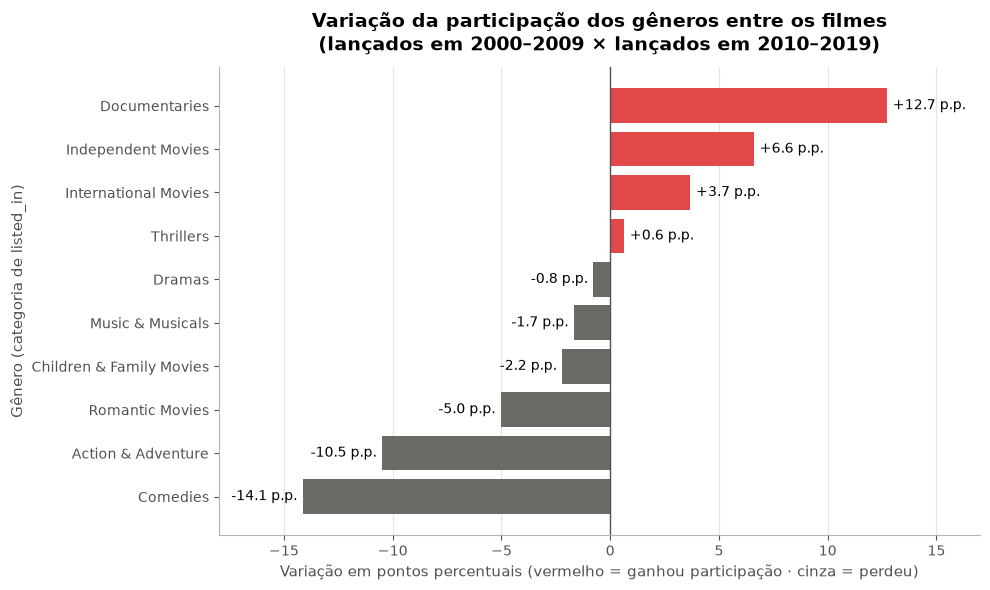

In [89]:
cores_variacao = []
for valor in variacao.values:
    if valor > 0:
        cores_variacao.append(COR_NETFLIX)   # ganhou participação
    else:
        cores_variacao.append('#6b6a64')     # perdeu participação

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(variacao.index, variacao.values, color=cores_variacao)
ax.bar_label(barras, fmt='%+.1f p.p.', padding=4)
ax.axvline(0, color='#52514e', linewidth=1)

ax.set_title('Variação da participação dos gêneros entre os filmes\n(lançados em 2000–2009 × lançados em 2010–2019)')
ax.set_xlabel('Variação em pontos percentuais (vermelho = ganhou participação · cinza = perdeu)')
ax.set_ylabel('Gênero (categoria de listed_in)')
ax.set_xlim(-18, 17)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)

plt.tight_layout()
plt.show()

**Resultados**, comparando filmes lançados em 2000–2009 (677) com os lançados em 2010–2019
(4.182):

- **Ganharam participação:** `Documentaries`, de 3,7% para 16,4% (**+12,7 p.p.**, mais que
  quadruplicou); `Independent Movies` (+6,6 p.p.); e `International Movies` (+3,7 p.p.).
- **Perderam participação:** `Comedies`, de 39,3% para 25,2% (**−14,1 p.p.**); e
  `Action & Adventure`, de 22,2% para 11,7% (**−10,5 p.p.**). `Romantic Movies` recua 5,0 p.p.
- **Praticamente estáveis:** `Dramas`, `Thrillers`, `Music & Musicals` e `Children & Family
  Movies`, com variações de até 2,2 p.p.

No período parcial **2020–2021** (794 filmes), documentários se mantêm em 16,4%, e `Children &
Family Movies` sobe para 15,5%. Já `Independent Movies` volta a 7,8%. Como o período tem menos de
dois anos, essas oscilações devem ser vistas com cautela.

**Conclusão:** entre os filmes do catálogo, os lançados na década de 2010 têm um perfil diferente
dos lançados na década de 2000. Os **documentários** ganharam muito espaço, e **comédias** e
**ação e aventura** perderam. `International Movies` já era a categoria mais frequente e
continuou crescendo.

**Cuidados na interpretação:**

1. Os percentuais descrevem **o que está no catálogo**, e não a produção mundial de cada
   década. Por exemplo, a Netflix pode ter preferido licenciar comédias e filmes de ação mais
   antigos, ou ter produzido muitos documentários recentes. A base não permite separar essas
   explicações.
2. As categorias de `listed_in` são **atribuídas pela Netflix** e incluem rótulos que não são
   gêneros no sentido estrito: `International Movies` indica a origem do filme, e
   `Independent Movies` indica o modo de produção.
3. Um filme com três categorias conta nas três. Os percentuais medem **presença** do gênero,
   e não uma divisão exclusiva do catálogo.

## 7.3 Estudantes — A diferença de desempenho entre os tipos de alimentação é semelhante nas três disciplinas?

**Justificativa:** a seção 5 analisou gênero, curso preparatório, escolaridade dos pais e grupo,
mas não o tipo de alimentação (`lunch`). Uma **hipótese** é que a alimentação gratuita ou
subsidiada (`free/reduced`) esteja ligada à condição socioeconômica das famílias. A base, porém,
**não informa renda nem a origem dos estudantes**, e por isso não permite confirmar essa
relação. Aqui, a variável é tratada apenas como o que ela registra: o tipo de alimentação.
Interessa saber se a diferença entre os grupos é igual em todas as disciplinas ou maior em
alguma delas.

**Seleção e tratamento:** usamos as três notas originais de `alunos_tratado`, sem
transformação. Comparamos médias e medianas de cada disciplina entre os dois grupos e a
diferença entre eles, em pontos de nota.

In [90]:
traducao_alimentacao = {'standard': 'Padrão', 'free/reduced': 'Gratuita/subsidiada'}

por_alimentacao = alunos_tratado.groupby('lunch')[notas].mean().rename(columns=nomes_disciplinas)
por_alimentacao['Média geral'] = alunos_tratado.groupby('lunch')['media_geral'].mean()
por_alimentacao['estudantes'] = alunos_tratado['lunch'].value_counts()
por_alimentacao.rename(index=traducao_alimentacao)

,Matemática,Leitura,Escrita,Média geral,estudantes
lunch,,,,,
Gratuita/subsidiada,58.92,64.65,63.02,62.20,355
Padrão,70.03,71.65,70.82,70.84,645


In [91]:
disciplinas = ['Matemática', 'Leitura', 'Escrita']

diferenca_media = por_alimentacao.loc['standard', disciplinas] - por_alimentacao.loc['free/reduced', disciplinas]

medianas_alimentacao = alunos_tratado.groupby('lunch')[notas].median().rename(columns=nomes_disciplinas)
diferenca_mediana = medianas_alimentacao.loc['standard'] - medianas_alimentacao.loc['free/reduced']

diferenca_geral = por_alimentacao.loc['standard', 'Média geral'] - por_alimentacao.loc['free/reduced', 'Média geral']
print(f'Diferença na média geral (padrão − gratuita): {diferenca_geral:.2f} pontos')

pd.DataFrame({
    'diferença das médias (padrão − gratuita)': diferenca_media,
    'diferença das medianas (padrão − gratuita)': diferenca_mediana,
})

Diferença na média geral (padrão − gratuita): 8.64 pontos


,diferença das médias (padrão − gratuita),diferença das medianas (padrão − gratuita)
Matemática,11.11,9.00
Leitura,7.00,7.00
Escrita,7.80,8.00


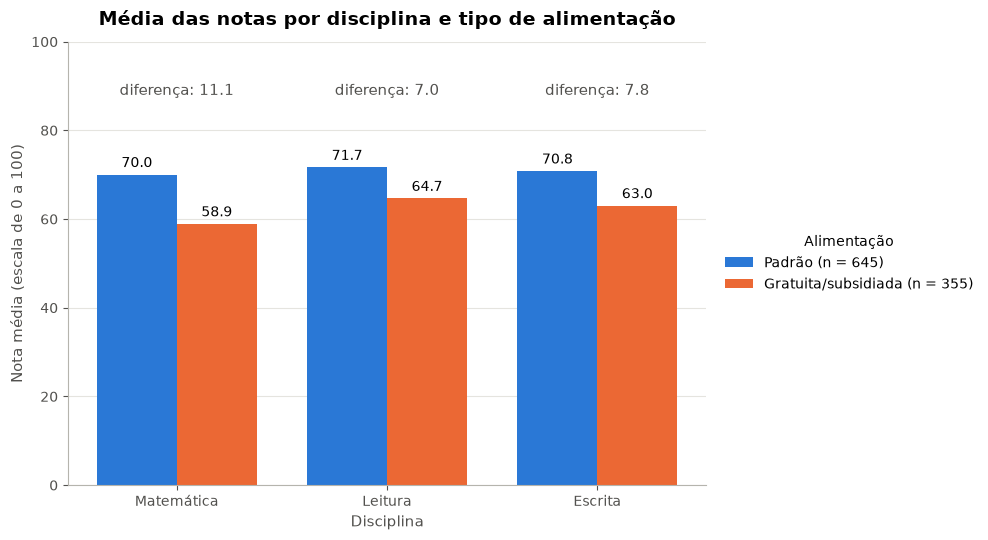

In [92]:
posicoes = range(len(disciplinas))
largura = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
barras_padrao = ax.bar([p - largura / 2 for p in posicoes], por_alimentacao.loc['standard', disciplinas],
                       width=largura, color=CORES[0], label='Padrão (n = 645)')
barras_gratuita = ax.bar([p + largura / 2 for p in posicoes], por_alimentacao.loc['free/reduced', disciplinas],
                         width=largura, color=CORES[1], label='Gratuita/subsidiada (n = 355)')
ax.bar_label(barras_padrao, fmt='%.1f', padding=3)
ax.bar_label(barras_gratuita, fmt='%.1f', padding=3)

# Diferença escrita acima de cada par de barras
for p, disciplina in zip(posicoes, disciplinas):
    ax.text(p, 88, f'diferença: {diferenca_media[disciplina]:.1f}', ha='center', color='#52514e', fontsize=11)

ax.set_title('Média das notas por disciplina e tipo de alimentação')
ax.set_xlabel('Disciplina')
ax.set_ylabel('Nota média (escala de 0 a 100)')
ax.set_xticks(list(posicoes))
ax.set_xticklabels(disciplinas)
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(title='Alimentação', loc='center left', bbox_to_anchor=(1.01, 0.5))

plt.tight_layout()
plt.show()

**Resultados:**

| Disciplina | Padrão (n = 645) | Gratuita/subsidiada (n = 355) | Diferença |
|---|---|---|---|
| Matemática | 70,03 | 58,92 | **11,11** |
| Leitura | 71,65 | 64,65 | 7,00 |
| Escrita | 70,82 | 63,02 | 7,80 |

**Conclusão:** **não, a diferença não é semelhante.** Os estudantes com alimentação padrão têm
média maior nas três disciplinas, mas a diferença é **bem maior em Matemática**: 11,1 pontos,
contra 7,0 em Leitura e 7,8 em Escrita, ou seja, cerca de 40% a 60% maior. As medianas
**reforçam** a diferença observada nas médias, com diferenças de 9, 7 e 8 pontos, também maiores
em Matemática. O tipo de alimentação está associado a uma diferença na média geral (8,6 pontos)
maior que a do gênero (3,7) e próxima da do curso preparatório (7,6), as duas comparadas na
seção 5.

**Cuidados na interpretação:** o resultado mostra **associação**, e não causa. Não é a refeição
que explica as notas. Uma **hipótese** é que o tipo de alimentação esteja relacionado a
condições socioeconômicas, como renda, acesso a material de estudo e apoio fora da escola. Mas
essas informações **não estão na base**, e a relação não pode ser verificada aqui. Pelo mesmo
motivo, não é possível dizer por que a diferença é maior em Matemática.

## 7.4 Estudantes — A associação entre curso preparatório e aprovação muda conforme o tipo de alimentação?

**Justificativa:** as questões 5.8 e 7.3 analisaram o curso preparatório e a alimentação
**separadamente**. Combinar as duas variáveis permite verificar se a diferença de aprovação
entre quem fez e quem não fez o curso aparece da mesma forma nos dois grupos de alimentação.

**Seleção e tratamento:**

- combinamos `lunch` e `test preparation course`, formando **quatro grupos**;
- a aprovação usa a coluna `aprovado`, criada na questão 5.6 (`media_geral >= 70`);
- para cada grupo, calculamos o **tamanho**, o número de aprovados, o **percentual de
  aprovação** e a média geral;
- a comparação é **descritiva**, como pede o enunciado, sem testes de hipótese.

In [93]:
# groupby com duas colunas: um grupo para cada combinação de alimentação e curso
quatro_grupos = alunos_tratado.groupby(['lunch', 'test preparation course']).agg(
    estudantes=('aprovado', 'count'),
    aprovados=('aprovado', 'sum'),
    media_geral=('media_geral', 'mean'),
)
quatro_grupos['aprovação (%)'] = quatro_grupos['aprovados'] / quatro_grupos['estudantes'] * 100

print('Soma dos tamanhos dos grupos:', quatro_grupos['estudantes'].sum(), '(deve ser 1000)')
quatro_grupos

Soma dos tamanhos dos grupos: 1000 (deve ser 1000)


estudantes  aprovados  media_geral  \
lunch        test preparation course                                       
free/reduced completed                       131         62        67.76   
             none                            224         48        58.95   
standard     completed                       227        156        75.51   
             none                            418        193        68.30   

                                      aprovação (%)  
lunch        test preparation course                 
free/reduced completed                        47.33  
             none                             21.43  
standard     completed                        68.72  
             none                             46.17

In [94]:
for tipo in ['standard', 'free/reduced']:
    com_curso = quatro_grupos.loc[(tipo, 'completed'), 'aprovação (%)']
    sem_curso = quatro_grupos.loc[(tipo, 'none'), 'aprovação (%)']
    print(f'Alimentação {traducao_alimentacao[tipo]:<20}: com curso {com_curso:.1f}% | sem curso {sem_curso:.1f}% '
          f'| diferença {com_curso - sem_curso:+.1f} p.p. | razão {com_curso / sem_curso:.2f}x')

Alimentação Padrão              : com curso 68.7% | sem curso 46.2% | diferença +22.6 p.p. | razão 1.49x
Alimentação Gratuita/subsidiada : com curso 47.3% | sem curso 21.4% | diferença +25.9 p.p. | razão 2.21x


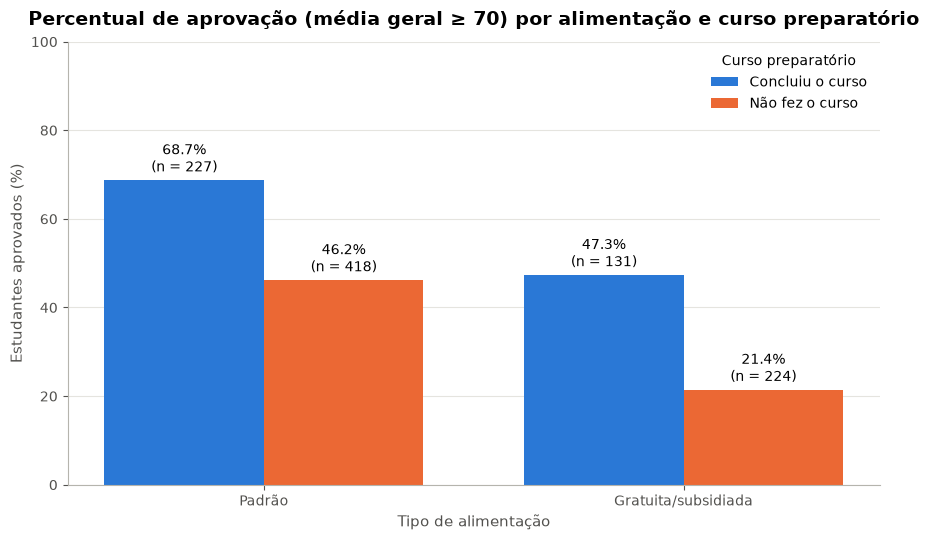

In [95]:
tipos_alimentacao = ['standard', 'free/reduced']
posicoes = range(len(tipos_alimentacao))
largura = 0.38

aprov_com = [quatro_grupos.loc[(t, 'completed'), 'aprovação (%)'] for t in tipos_alimentacao]
aprov_sem = [quatro_grupos.loc[(t, 'none'), 'aprovação (%)'] for t in tipos_alimentacao]
n_com = [quatro_grupos.loc[(t, 'completed'), 'estudantes'] for t in tipos_alimentacao]
n_sem = [quatro_grupos.loc[(t, 'none'), 'estudantes'] for t in tipos_alimentacao]

fig, ax = plt.subplots(figsize=(9, 5.5))
barras_com = ax.bar([p - largura / 2 for p in posicoes], aprov_com, width=largura, color=CORES[0], label='Concluiu o curso')
barras_sem = ax.bar([p + largura / 2 for p in posicoes], aprov_sem, width=largura, color=CORES[1], label='Não fez o curso')

ax.bar_label(barras_com, labels=[f'{a:.1f}%\n(n = {n})' for a, n in zip(aprov_com, n_com)], padding=3)
ax.bar_label(barras_sem, labels=[f'{a:.1f}%\n(n = {n})' for a, n in zip(aprov_sem, n_sem)], padding=3)

ax.set_title('Percentual de aprovação (média geral ≥ 70) por alimentação e curso preparatório')
ax.set_xlabel('Tipo de alimentação')
ax.set_ylabel('Estudantes aprovados (%)')
ax.set_xticks(list(posicoes))
ax.set_xticklabels([traducao_alimentacao[t] for t in tipos_alimentacao])
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
ax.legend(title='Curso preparatório', loc='upper right')

plt.tight_layout()
plt.show()

**Resultados:**

| Alimentação | Curso | Estudantes | Aprovação |
|---|---|---|---|
| Padrão | concluiu | 227 | **68,7%** |
| Padrão | não fez | 418 | 46,2% |
| Gratuita/subsidiada | concluiu | 131 | 47,3% |
| Gratuita/subsidiada | não fez | 224 | **21,4%** |

**Conclusão:**

- A associação entre curso e aprovação **aparece nos dois grupos de alimentação, com
  intensidade parecida em pontos percentuais**: +22,6 p.p. na alimentação padrão e +25,9 p.p. na
  gratuita/subsidiada. A diferença entre os dois aumentos, de cerca de 3 p.p., é pequena. Sem
  um teste estatístico, não dá para afirmar que ela seja real e não fruto da variação natural
  da amostra.
- Em termos **relativos**, a diferença é maior no grupo de alimentação gratuita/subsidiada: a
  aprovação de quem fez o curso é **2,2 vezes** a de quem não fez, contra 1,5 vez no grupo de
  alimentação padrão. Isso acontece porque a aprovação desse grupo parte de um nível bem mais
  baixo (21,4%).
- **Achado:** estudantes com alimentação gratuita/subsidiada **que fizeram o curso** têm
  aprovação (47,3%) praticamente igual à dos estudantes com alimentação padrão **que não
  fizeram** (46,2%). Os dois extremos ficam muito distantes: 68,7% × 21,4%.

**Cuidados na interpretação:** os grupos têm tamanhos suficientes para uma comparação
descritiva, com pelo menos 131 estudantes cada. Ainda assim, o resultado **não prova que o
curso compense a desvantagem associada à alimentação**. Quem escolheu fazer o curso pode ser
diferente de quem não fez em características que a base não registra, como motivação e apoio
familiar.

## 7.5 Conferência final: os DataFrames originais foram preservados?

Todas as transformações foram feitas nas cópias `netflix_tratado` e `alunos_tratado`. A célula
abaixo confirma isso, comparando os DataFrames originais com uma nova leitura dos arquivos CSV.

In [96]:
print('netflix continua idêntico ao arquivo CSV?', netflix.equals(pd.read_csv(ARQUIVO_NETFLIX)))
print('alunos continua idêntico ao arquivo CSV? ', alunos.equals(pd.read_csv(ARQUIVO_ALUNOS)))
print()
print('Colunas criadas apenas em netflix_tratado:', [c for c in netflix_tratado.columns if c not in netflix.columns])
print('Colunas criadas apenas em alunos_tratado :', [c for c in alunos_tratado.columns if c not in alunos.columns])

netflix continua idêntico ao arquivo CSV? True


alunos continua idêntico ao arquivo CSV?  True

Colunas criadas apenas em netflix_tratado: ['data_adicao', 'ano_adicao', 'decada', 'periodo']
Colunas criadas apenas em alunos_tratado : ['media_geral', 'aprovado']


---
# 8. Conclusões

## Descobertas sobre a Netflix

1. **O catálogo é recente, e as inclusões registradas se concentram a partir de 2016.** Cerca de
   85% dos títulos foram lançados de 2010 em diante, e o pico de lançamentos é 2018. Entre os
   títulos presentes na base, as datas de inclusão se concentram entre 2016 e 2019 e, desde
   2017, superam os lançamentos de cada ano. Isso mostra que muitos títulos de anos anteriores
   entraram no catálogo depois. **Atenção:** a base registra apenas os títulos disponíveis em
   2021. Títulos incluídos e removidos antes disso não aparecem, então essas contagens **não
   representam necessariamente o crescimento histórico completo do catálogo**. Por isso, distinguir
   `release_year` de `date_added` foi essencial: os dois contam histórias diferentes.
2. **As séries ganharam espaço entre os títulos recentes.** O catálogo tem 70% de filmes no
   total, mas essa proporção não é constante. Entre os títulos lançados em 2020–2021, quase
   metade são séries, contra cerca de 16% nos anos 2000 (investigação 7.1). Uma média geral do
   catálogo esconde essa mudança de perfil.
3. **A produção é concentrada geograficamente.** Os Estados Unidos participam de quase metade
   dos títulos com país informado, mais de três vezes o total da Índia, 2ª colocada. A Índia,
   por sua vez, aparece à frente do Reino Unido, e o top 10 tem forte presença asiática.
4. **O perfil dos filmes mudou entre as décadas.** Entre os filmes do catálogo, os
   documentários passam de 3,7% dos lançados nos anos 2000 para 16,4% dos lançados nos anos
   2010, enquanto comédias e ação e aventura perdem espaço (investigação 7.2).
5. **Rankings por quantidade refletem o formato, e não o prestígio.** Os diretores com mais
   títulos assinam animações infantis e especiais de stand-up, formatos com muitos títulos
   curtos. Nomes como Martin Scorsese aparecem empatados no fim do top 10.

## Descobertas sobre o desempenho dos estudantes

1. **Menos da metade dos estudantes foi aprovada (45,9%), e Matemática é o principal
   obstáculo.** É a disciplina com menor média e a única em que menos da metade (40,9%) atinge
   70. Doze estudantes têm média exatamente 70, por isso o uso de "≥" no critério muda o
   resultado.
2. **O tipo de alimentação está associado à maior diferença de desempenho** entre os fatores
   analisados: 8,6 pontos na média geral, mais que o dobro da diferença entre gêneros. A
   diferença é maior justamente em Matemática, com 11,1 pontos (investigação 7.3).
3. **O curso preparatório está associado a uma aprovação maior nos dois grupos de
   alimentação.** Os estudantes com alimentação gratuita/subsidiada que fizeram o curso têm
   aprovação próxima à dos estudantes com alimentação padrão que não fizeram (investigação
   7.4).
4. **Médias agregadas podem esconder diferenças opostas.** O grupo feminino tem média geral
   maior, mas o grupo masculino tem média maior em Matemática. A vantagem feminina vem de
   Leitura e Escrita (gráfico 6.5).
5. **A escolaridade dos pais acompanha o desempenho, mas não de forma perfeitamente
   crescente.** O grupo de pais com ensino médio completo tem média menor que o de ensino médio
   incompleto.

## Características das bases que dificultaram as análises

**Netflix:**

- **campos com vários valores** na mesma célula (`country`, `director`, `cast`, `listed_in`),
  que exigiram separar os nomes antes de qualquer contagem;
- **muitos valores ausentes**, sobretudo em `director`, que falta em 91% das séries;
- **erros de preenchimento:** duração gravada em `rating`, vírgulas sobrando em `country`,
  quase-duplicatas e variação de grafia de nomes ("Raúl Campos" × "Raúl Campos Delgado");
- **tipos inadequados:** datas e durações armazenadas como texto, com unidades misturadas
  (minutos e temporadas);
- **categorias diferentes para filmes e séries** em `listed_in`, que criam tendências falsas se
  os dois tipos forem misturados;
- **significado ambíguo de `release_year` nas séries**, com 14 títulos incluídos no catálogo
  antes do próprio ano de lançamento.

**Estudantes:**

- **ausência de identificador**, o que obrigou a usar o índice da linha e a definir um critério
  de desempate no top 10;
- **grupos étnicos anonimizados** (A a E): eles permitem comparações numéricas, como na questão
  5.10, mas o significado de cada letra não está documentado. Por isso, os resultados não
  podem ser associados a grupos reais da população;
- **poucas variáveis, todas categóricas.** Não há idade, escola, renda nem frequência, o que
  limita a explicação das diferenças;
- **nota 0 sem contexto:** não é possível saber se indica ausência na prova.

## Qual base permitiu análises mais interessantes?

A **Netflix** permitiu análises mais interessantes, por três motivos:

1. **Dimensão temporal:** a base tem duas datas, lançamento e inclusão no catálogo. Isso
   permitiu estudar mudanças ao longo do tempo, como a maior presença de séries, a mudança nos
   gêneros e a distribuição das datas de inclusão, algo impossível na base de estudantes, que é uma
   "fotografia" de um único momento.
2. **Riqueza e desafio dos dados:** os problemas de qualidade, como campos com vários valores,
   quase-duplicatas e valores na coluna errada, exigiram decisões de tratamento justificadas.
   Essas decisões mudaram os resultados de forma visível, como na contagem de países e no
   "efeito denominador" dos gêneros.
3. **Variedade de perguntas:** tipos, países, diretores, gêneros, classificações e durações
   permitiram explorar o catálogo sob muitos ângulos.

A base de **estudantes**, por outro lado, é **limpa**: não tem valores ausentes, duplicatas
nem erros de preenchimento. Isso permitiu comparações entre grupos mais diretas e combinações
entre variáveis, como alimentação × curso. Ela **não é totalmente equilibrada**, porém: alguns
grupos têm tamanhos bem diferentes, como 59 a 226 estudantes por nível de escolaridade dos
pais e 89 a 319 por grupo étnico. Os grupos menores dão resultados menos estáveis. Ela foi mais adequada para comparar grupos. A Netflix foi mais rica para a exploração
como um todo.

## Limitações das análises realizadas

1. **Análise apenas descritiva:** como orientado no enunciado, não foram feitos testes de
   hipótese. Diferenças pequenas, como os cerca de 3 p.p. da investigação 7.4, podem ser fruto
   da variação natural da amostra.
2. **Associação não é causalidade:** nenhuma das diferenças observadas entre os estudantes,
   seja por curso, alimentação, gênero, escolaridade ou grupo, permite afirmar que uma
   característica cause melhor ou pior desempenho. Os estudantes não foram distribuídos
   aleatoriamente entre os grupos.
3. **A Netflix é uma "fotografia" do catálogo em setembro de 2021:** títulos que saíram antes
   disso não aparecem, 2021 está incompleto, e os resultados descrevem o **catálogo**, e não a
   produção audiovisual mundial.
4. **Decisões de tratamento influenciam os números:** remover 4 quase-duplicatas, manter os
   ausentes, contar coproduções para cada país e restringir os gêneros aos filmes são escolhas
   justificadas, mas outras escolhas levariam a números um pouco diferentes.
5. **Amostras pequenas em alguns grupos:** décadas antigas da Netflix e o grupo de pais com
   mestrado (59 estudantes) têm poucos registros, e seus resultados são menos estáveis.
6. **Origem e representatividade da base de estudantes:** a base não documenta escola, local
   nem forma de coleta. Os 1.000 estudantes não podem ser tratados como representativos de
   nenhuma população específica.